# Task 1 · T1.1: CNN Knowledge Distillation (EfficientNet-B7 → EfficientNet-B0) on ImageNet-100
- **Teacher:** pretrained EfficientNet-B7, frozen. We keep only the 100 logits that match the ImageNet-100 classes.
- **Student A:** EfficientNet-B0 from random weights, trained with cross-entropy only.
- **Student B:** same initial weights, trained with L = (1−λ)·CE + λ·T²·KL(p_T‖p_S), with T = 3 and λ = 0.5.

## Imports and settings

In [2]:
import os, io, json, time, subprocess
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from torchvision.models import efficientnet_b0, efficientnet_b7, EfficientNet_B7_Weights
from huggingface_hub import hf_hub_download

# ---------------- Settings ----------------
SEED         = 42
EPOCHS       = 5
BATCH_SIZE   = 32
LR           = 1e-3          # AdamW
WEIGHT_DECAY = 1e-4
T            = 3.0           # KD temperature
LAMBDA       = 0.5           # KD weight
TRAIN_PER_CLASS = 20         # 100 x 20 = 2000 train images
VAL_PER_CLASS   = 5          # 100 x 5  = 500 val images
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
print("Device:", DEVICE)

Device: mps


### Functions

In [4]:
# ============ 1. Downloads ============
def download_teacher_weights():
    """Download B7 weights into the PyTorch cache (resumable)."""
    url = EfficientNet_B7_Weights.IMAGENET1K_V1.url
    path = os.path.join(torch.hub.get_dir(), "checkpoints", os.path.basename(url))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if not os.path.exists(path):
        subprocess.run(["curl", "-L", "-C", "-", "--retry", "50", "-o", path, url], check=True)


def download_imagenet100():
    """Download ImageNet-100 from Hugging Face (public, no token).
    Gets the validation file and only as many train files as needed."""
    def get(name):
        return hf_hub_download("clane9/imagenet-100", f"data/{name}",
                               repo_type="dataset", local_dir="data/hf")

    val_file = get("validation-00000-of-00001.parquet")
    train_files, counts, shard = [], pd.Series(dtype=float), 0
    while len(counts) < 100 or counts.min() < TRAIN_PER_CLASS:
        f = get(f"train-{shard:05d}-of-00017.parquet")
        train_files.append(f)
        labels = pd.read_parquet(f, columns=["label"])["label"]
        counts = counts.add(labels.value_counts(), fill_value=0)
        shard += 1
    return train_files, val_file


# ============ 2. Data ============
TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def load_subset(files, per_class):
    """Fixed stratified subset: `per_class` images per class -> (images, labels)."""
    df = pd.concat(pd.read_parquet(f) for f in files)
    df = df.groupby("label").sample(n=per_class, random_state=SEED)
    images = [TRANSFORM(Image.open(io.BytesIO(img["bytes"])).convert("RGB")) for img in df["image"]]
    return torch.stack(images), torch.tensor(df["label"].values)


def get_class_names(parquet_file):
    """ImageNet-100 class names in label order (stored in the parquet metadata)."""
    meta = json.loads(pq.read_schema(parquet_file).metadata[b"huggingface"])
    return meta["info"]["features"]["label"]["names"]


def build_class_mapping(class_names, teacher, X, y):
    """Map each ImageNet-100 class to the teacher's ImageNet-1K output index."""
    in1k_names = EfficientNet_B7_Weights.IMAGENET1K_V1.meta["categories"]
    mapping = []
    for c, name in enumerate(class_names):
        short = name.split(",")[0].strip()
        matches = [i for i, n in enumerate(in1k_names) if n == short]
        if len(matches) > 1:   # duplicate name (e.g. "crane"): pick the one the teacher predicts
            logits = predict(teacher, X[y == c])
            matches = [max(matches, key=lambda i: logits[:, i].mean().item())]
        assert len(matches) == 1, f"No ImageNet-1K match for '{name}'"
        mapping.append(matches[0])

    pd.DataFrame({"student_class": range(100), "imagenet100_name": class_names,
                  "teacher_index": mapping, "teacher_name": [in1k_names[i] for i in mapping]}
                 ).to_csv("outputs/class_mapping.csv", index=False)
    return torch.tensor(mapping)


# ============ 3. Models ============
def load_teacher():
    """Pretrained EfficientNet-B7, frozen."""
    model = efficientnet_b7(weights=EfficientNet_B7_Weights.IMAGENET1K_V1).eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad = False
    return model


def make_student():
    """Random EfficientNet-B0 with a 100-class head."""
    model = efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(1280, 100)
    return model


def make_identical_students():
    """Two students that start from exactly the same random weights."""
    torch.manual_seed(SEED)
    init_weights = make_student().state_dict()
    student_A, student_B = make_student(), make_student()
    student_A.load_state_dict(init_weights)
    student_B.load_state_dict(init_weights)
    return student_A, student_B


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# ============ 4. Evaluation ============
@torch.no_grad()
def predict(model, X, batch_size=32):
    """Logits for all images in X (returned on CPU)."""
    model.eval()
    outputs = [model(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)]
    return torch.cat(outputs)


def accuracy(logits, labels):
    """Top-1 and Top-5 accuracy in %."""
    top5 = logits.topk(5, dim=1).indices
    top1_acc = (top5[:, 0] == labels).float().mean().item() * 100
    top5_acc = (top5 == labels[:, None]).any(dim=1).float().mean().item() * 100
    return top1_acc, top5_acc


@torch.inference_mode()
def measure_latency(model, warmup=10, runs=20):
    """Median latency (ms) at batch size 1. Input is already on device -> no data loading."""
    model.eval().to(DEVICE)
    x = torch.randn(1, 3, 224, 224, device=DEVICE)
    sync = torch.mps.synchronize if DEVICE.type == "mps" else (lambda: None)
    for _ in range(warmup):
        model(x)
    times = []
    for _ in range(runs):
        sync()
        start = time.perf_counter()
        model(x)
        sync()
        times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))


# ============ 5. Training ============
def kd_loss(student_logits, teacher_logits, labels):
    """L = (1 - lambda) * CE + lambda * T^2 * KL(p_teacher || p_student)."""
    ce = F.cross_entropy(student_logits, labels)
    kl = F.kl_div(F.log_softmax(student_logits / T, dim=1),
                  F.softmax(teacher_logits / T, dim=1), reduction="batchmean")
    return (1 - LAMBDA) * ce + LAMBDA * T * T * kl, ce


def train_student(model, X_train, y_train, X_val, y_val, teacher_logits=None):
    """Train a student. teacher_logits=None -> CE only (A); otherwise CE + KD (B)."""
    torch.manual_seed(SEED)                      # same batch order for both students
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, updates = [], 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_train))
        total_ce = 0.0

        for i in range(0, len(X_train), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x, y = X_train[idx].to(DEVICE), y_train[idx].to(DEVICE)
            logits = model(x)

            if teacher_logits is None:
                loss = ce = F.cross_entropy(logits, y)
            else:
                loss, ce = kd_loss(logits, teacher_logits[idx].to(DEVICE), y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            updates += 1
            total_ce += ce.item() * len(idx)

        top1, top5 = accuracy(predict(model, X_val), y_val)
        history.append({"epoch": epoch, "train_ce": total_ce / len(X_train), "val_top1": top1, "val_top5": top5})
        print(f"  epoch {epoch}: train CE {history[-1]['train_ce']:.3f} | val top-1 {top1:.2f}% | top-5 {top5:.2f}%")

    return pd.DataFrame(history), updates

### Run T1.1

In [8]:
# 1. Download teacher weights and data
download_teacher_weights()
train_files, val_file = download_imagenet100()

# 2. Models
teacher = load_teacher()
student_A, student_B = make_identical_students()

# 3. Data subset (2000 train / 500 val) and class mapping
X_train, y_train = load_subset(train_files, TRAIN_PER_CLASS)
X_val,   y_val   = load_subset([val_file], VAL_PER_CLASS)
teacher_idx = build_class_mapping(get_class_names(val_file), teacher, X_train, y_train)
print("Train:", tuple(X_train.shape), "| Val:", tuple(X_val.shape))

# 4. Teacher logits (only the 100 matching classes), computed once
teacher_train_logits = predict(teacher, X_train)[:, teacher_idx]
teacher_val_logits   = predict(teacher, X_val)[:, teacher_idx]

# 5. Train both students
print("Student A (CE only)")
history_A, updates_A = train_student(student_A, X_train, y_train, X_val, y_val)
print("Student B (CE + KD)")
history_B, updates_B = train_student(student_B, X_train, y_train, X_val, y_val, teacher_train_logits)

Train: (2000, 3, 224, 224) | Val: (500, 3, 224, 224)
Student A (CE only)
  epoch 1: train CE 4.711 | val top-1 1.00% | top-5 5.20%
  epoch 2: train CE 4.546 | val top-1 2.20% | top-5 9.80%
  epoch 3: train CE 4.477 | val top-1 4.00% | top-5 11.40%
  epoch 4: train CE 4.374 | val top-1 3.20% | top-5 12.60%
  epoch 5: train CE 4.289 | val top-1 4.40% | top-5 15.60%
Student B (CE + KD)
  epoch 1: train CE 4.669 | val top-1 1.20% | top-5 5.20%
  epoch 2: train CE 4.493 | val top-1 4.00% | top-5 13.00%
  epoch 3: train CE 4.370 | val top-1 2.20% | top-5 13.40%
  epoch 4: train CE 4.294 | val top-1 3.20% | top-5 15.80%
  epoch 5: train CE 4.221 | val top-1 5.40% | top-5 18.00%


### Results and curves

,Model,Top-1 (%) [measured],Top-5 (%) [measured],Params (M) [analytical],Median latency (ms) [measured],Optimizer updates
0,Teacher B7 (frozen),88.4,97.8,66.35,18.74,0
1,Student A (CE),4.4,15.6,4.14,5.50,315
2,Student B (CE+KD),5.4,18.0,4.14,6.50,315


Seed: 42 | Optimizer updates per student: 315


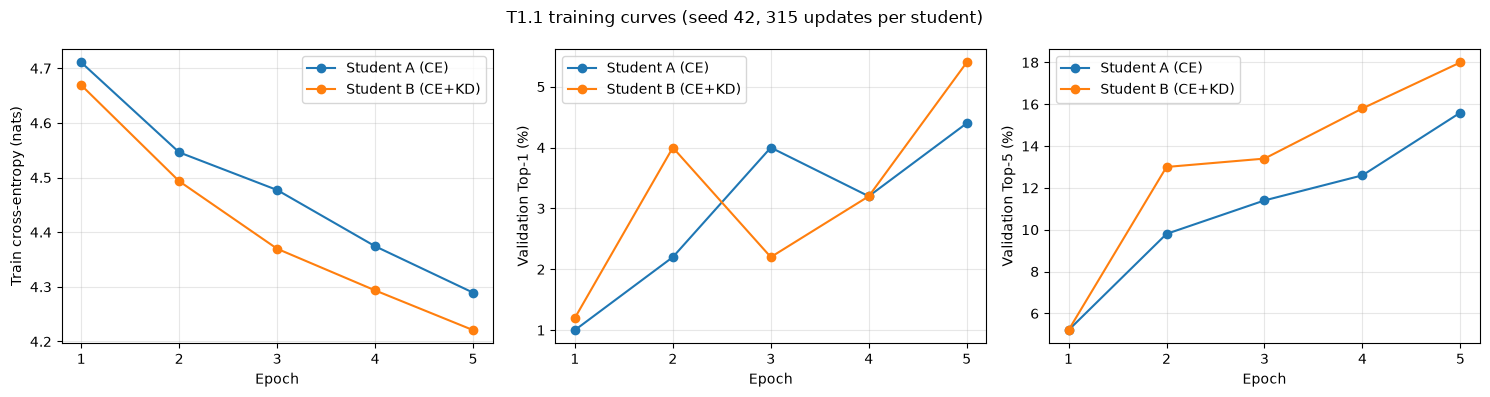

In [9]:
# ---- Results table ----
models = [
    ("Teacher B7 (frozen)", teacher,   teacher_val_logits,          0),
    ("Student A (CE)",      student_A, predict(student_A, X_val),   updates_A),
    ("Student B (CE+KD)",   student_B, predict(student_B, X_val),   updates_B),
]
rows = []
for name, model, logits, updates in models:
    top1, top5 = accuracy(logits, y_val)
    rows.append({
        "Model": name,
        "Top-1 (%) [measured]": round(top1, 2),
        "Top-5 (%) [measured]": round(top5, 2),
        "Params (M) [analytical]": round(count_params(model) / 1e6, 2),
        "Median latency (ms) [measured]": round(measure_latency(model), 2),
        "Optimizer updates": updates,
    })
results = pd.DataFrame(rows)
results.to_csv("outputs/t1_1_results.csv", index=False)
display(results)
print(f"Seed: {SEED} | Optimizer updates per student: {updates_A}")

# ---- Training curves ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plots = [("train_ce", "Train cross-entropy (nats)"),
         ("val_top1", "Validation Top-1 (%)"),
         ("val_top5", "Validation Top-5 (%)")]
for ax, (column, ylabel) in zip(axes, plots):
    ax.plot(history_A["epoch"], history_A[column], "o-", label="Student A (CE)")
    ax.plot(history_B["epoch"], history_B[column], "o-", label="Student B (CE+KD)")
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle(f"T1.1 training curves (seed {SEED}, {updates_A} updates per student)")
plt.tight_layout()
plt.savefig("outputs/t1_1_curves.png", dpi=150)
plt.show()

## T1.2-1 · Verify the feature shapes

In [10]:
x = X_train[:2].to(DEVICE)                      

with torch.no_grad():
    t_feat = teacher.features[:2](x)            
    s_feat = make_student().to(DEVICE).features[:1](x)  

print("Teacher features[1] output:", tuple(t_feat.shape))
print("Student features[0] output:", tuple(s_feat.shape))
assert t_feat.shape == s_feat.shape, "Shapes differ - choose other layers"

Teacher features[1] output: (2, 32, 112, 112)
Student features[0] output: (2, 32, 112, 112)


### T1.2-2 · Functions for hint training

In [12]:
HINT_WEIGHT = 0.05
FT_EPOCHS = 2

def student_forward_with_feature(model, x):
    """Run the student and also return its features[0] output."""
    h = model.features[0](x)                      # hint layer (32 x 112 x 112)
    z = model.features[1:](h)
    z = model.avgpool(z).flatten(1)
    return model.classifier(z), h


def load_student_B():
    """Fresh copy of the T1.1 logit-KD student (Student B)."""
    model = make_student()
    model.load_state_dict(torch.load("outputs/student_B.pt"))
    return model.to(DEVICE)


def finetune(model, hint_weight):
    """2 more epochs with L = L_KD + hint_weight * MSE(h_S, h_T).
    hint_weight = 0 -> KD-only control run."""
    torch.manual_seed(SEED)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    epoch_log, step_log, updates = [], [], 0

    top1, top5 = accuracy(predict(model, X_val), y_val)
    epoch_log.append({"epoch": 0, "hint_loss": float("nan"), "val_top1": top1, "val_top5": top5})

    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_train))
        hint_sum = 0.0
        for i in range(0, len(X_train), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x, y = X_train[idx].to(DEVICE), y_train[idx].to(DEVICE)

            with torch.no_grad():
                h_teacher = teacher.features[:2](x)          # frozen teacher feature
            logits, h_student = student_forward_with_feature(model, x)

            loss_kd, _ = kd_loss(logits, teacher_train_logits[idx].to(DEVICE), y)
            loss_hint = F.mse_loss(h_student, h_teacher)
            loss = loss_kd + hint_weight * loss_hint

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            updates += 1
            hint_sum += loss_hint.item() * len(idx)
            step_log.append({"update": updates, "hint_loss": loss_hint.item()})

        top1, top5 = accuracy(predict(model, X_val), y_val)
        epoch_log.append({"epoch": epoch, "hint_loss": hint_sum / len(X_train),
                          "val_top1": top1, "val_top5": top5})
        print(f"  epoch {epoch}: hint MSE {epoch_log[-1]['hint_loss']:.4f} | "
              f"val top-1 {top1:.2f}% | top-5 {top5:.2f}%")

    return model, pd.DataFrame(epoch_log), pd.DataFrame(step_log), updates

### T1.2-3 · Run

In [13]:
torch.save(student_B.state_dict(), "outputs/student_B.pt")    # make sure the T1.1 checkpoint exists

print("With hint (L_KD + 0.05 * L_hint)")
student_hint, hist_hint, steps_hint, upd_hint = finetune(load_student_B(), HINT_WEIGHT)

print("Control: KD only, same 2 epochs")
student_ctrl, hist_ctrl, steps_ctrl, upd_ctrl = finetune(load_student_B(), 0.0)

torch.save(student_hint.state_dict(), "outputs/student_T1_2_hint.pt")

With hint (L_KD + 0.05 * L_hint)
  epoch 1: hint MSE 32.4349 | val top-1 5.20% | top-5 19.00%
  epoch 2: hint MSE 31.9339 | val top-1 3.20% | top-5 16.20%
Control: KD only, same 2 epochs
  epoch 1: hint MSE 32.7032 | val top-1 5.40% | top-5 21.00%
  epoch 2: hint MSE 32.7153 | val top-1 5.00% | top-5 17.40%


### T1.2-4 · Results and curves

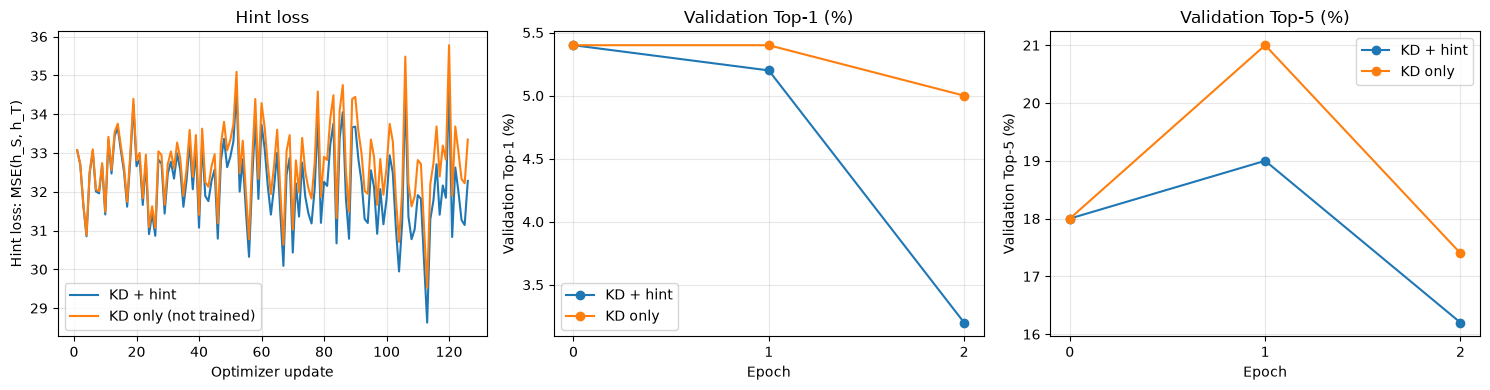

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: hint loss per optimizer update
axes[0].plot(steps_hint["update"], steps_hint["hint_loss"], label="KD + hint")
axes[0].plot(steps_ctrl["update"], steps_ctrl["hint_loss"], label="KD only (not trained)")
axes[0].set_xlabel("Optimizer update")
axes[0].set_ylabel("Hint loss: MSE(h_S, h_T)")
axes[0].set_title("Hint loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plots 2 & 3: validation Top-1 / Top-5 per epoch
for ax, col, ylabel in [(axes[1], "val_top1", "Validation Top-1 (%)"),
                        (axes[2], "val_top5", "Validation Top-5 (%)")]:
    ax.plot(hist_hint["epoch"], hist_hint[col], marker="o", label="KD + hint")
    ax.plot(hist_ctrl["epoch"], hist_ctrl[col], marker="o", label="KD only")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_xticks(hist_hint["epoch"])
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## T1.3-1 · Shapes and adapter

In [19]:
x = X_train[:2].to(DEVICE)
with torch.no_grad():
    h_T = teacher.features[:6](x)                         # teacher features[5]
    h_S = load_student_B().features[:5](x)                # student features[4]

adapter = nn.Conv2d(80, 224, kernel_size=1).to(DEVICE)     # r_theta: 80 -> 224 channels
adapter_params = sum(p.numel() for p in adapter.parameters())

print("Teacher features[5]        :", tuple(h_T.shape))
print("Student features[4]        :", tuple(h_S.shape))
print("Adapter(student) output    :", tuple(adapter(h_S).shape))
print("Adapter parameters         :", adapter_params, "(80*224 weights + 224 biases)")
assert adapter(h_S).shape == h_T.shape

Teacher features[5]        : (2, 224, 14, 14)
Student features[4]        : (2, 80, 14, 14)
Adapter(student) output    : (2, 224, 14, 14)
Adapter parameters         : 18144 (80*224 weights + 224 biases)


### T1.3-2 · Check the gradient flow

In [20]:
student = load_student_B()
adapter = nn.Conv2d(80, 224, kernel_size=1).to(DEVICE)

x = X_train[:8].to(DEVICE)
with torch.no_grad():
    h_T = teacher.features[:6](x)
loss = F.mse_loss(adapter(student.features[:5](x)), h_T)
loss.backward()

print("Student gets gradient :", student.features[0][0].weight.grad.abs().sum().item() > 0)
print("Adapter gets gradient :", adapter.weight.grad.abs().sum().item() > 0)
print("Teacher frozen        :", all(p.grad is None and not p.requires_grad for p in teacher.parameters()))

Student gets gradient : True
Adapter gets gradient : True
Teacher frozen        : True


### T1.3-3 · Train with the adapter (2 epochs) 

In [21]:
def student_forward_deep(model, x):
    """Run the student and also return its features[4] output."""
    h = model.features[:5](x)
    z = model.features[5:](h)
    z = model.avgpool(z).flatten(1)
    return model.classifier(z), h


# Teacher features[5] for all training images, computed once (no augmentation -> identical every epoch)
with torch.no_grad():
    teacher_train_feats = torch.cat([teacher.features[:6](X_train[i:i + 32].to(DEVICE)).cpu()
                                     for i in range(0, len(X_train), 32)])


def finetune_with_adapter(model, adapter):
    """2 epochs, L = L_KD + 0.05 * MSE(adapter(h_S), h_T); student and adapter trained jointly."""
    torch.manual_seed(SEED)
    params = list(model.parameters()) + list(adapter.parameters())
    optimizer = torch.optim.AdamW(params, lr=LR, weight_decay=WEIGHT_DECAY)
    epoch_log, step_log, updates = [], [], 0

    top1, top5 = accuracy(predict(model, X_val), y_val)
    epoch_log.append({"epoch": 0, "hint_loss": float("nan"), "val_top1": top1, "val_top5": top5})

    for epoch in range(1, FT_EPOCHS + 1):
        model.train(); adapter.train()
        order = torch.randperm(len(X_train))
        hint_sum = 0.0
        for i in range(0, len(X_train), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x, y = X_train[idx].to(DEVICE), y_train[idx].to(DEVICE)

            logits, h_student = student_forward_deep(model, x)
            loss_kd, _ = kd_loss(logits, teacher_train_logits[idx].to(DEVICE), y)
            loss_hint = F.mse_loss(adapter(h_student), teacher_train_feats[idx].to(DEVICE))
            loss = loss_kd + HINT_WEIGHT * loss_hint

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            updates += 1
            hint_sum += loss_hint.item() * len(idx)
            step_log.append({"update": updates, "hint_loss": loss_hint.item()})

        top1, top5 = accuracy(predict(model, X_val), y_val)
        epoch_log.append({"epoch": epoch, "hint_loss": hint_sum / len(X_train),
                          "val_top1": top1, "val_top5": top5})
        print(f"  epoch {epoch}: hint MSE {epoch_log[-1]['hint_loss']:.4f} | "
              f"val top-1 {top1:.2f}% | top-5 {top5:.2f}%")

    return model, epoch_log and pd.DataFrame(epoch_log), pd.DataFrame(step_log), updates


print("KD + adapter hint")
adapter = nn.Conv2d(80, 224, kernel_size=1).to(DEVICE)
student_adapt, hist_adapt, steps_adapt, upd_adapt = finetune_with_adapter(load_student_B(), adapter)
torch.save({"student": student_adapt.state_dict(), "adapter": adapter.state_dict()}, "outputs/student_T1_3_adapter.pt")

KD + adapter hint
  epoch 1: hint MSE 41.2942 | val top-1 6.00% | top-5 19.60%
  epoch 2: hint MSE 35.8263 | val top-1 3.40% | top-5 19.00%


### T1.3-4 · Results and curves

,Run (all start from T1.1 Student B),Val Top-1 (%),Val Top-5 (%),Final hint MSE,Adapter params,Extra updates
0,"KD only (control, from T1.2)",5.0,17.4,NaN,0,126
1,"T1.2: KD + hint, no adapter (features[1] / fea...",3.2,16.2,31.9339,0,126
2,"T1.3: KD + hint, 1x1 adapter (features[5] / fe...",3.4,19.0,35.8263,18144,126


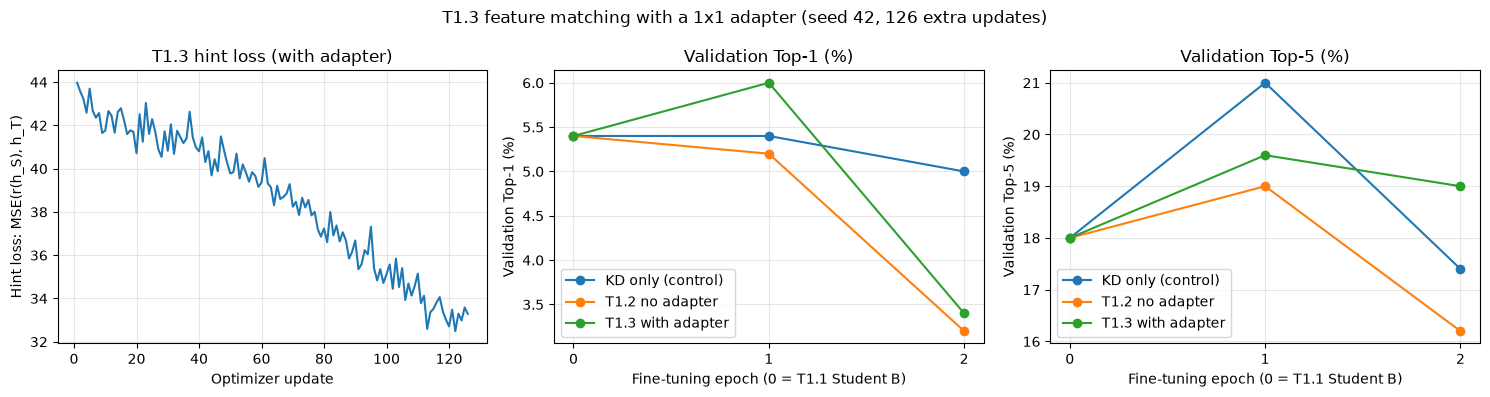

In [23]:
table = pd.DataFrame([
    {"Run (all start from T1.1 Student B)": "KD only (control, from T1.2)",
     "Val Top-1 (%)": hist_ctrl.val_top1.iloc[-1], "Val Top-5 (%)": hist_ctrl.val_top5.iloc[-1],
     "Final hint MSE": float("nan"), "Adapter params": 0, "Extra updates": upd_ctrl},
    {"Run (all start from T1.1 Student B)": "T1.2: KD + hint, no adapter (features[1] / features[0])",
     "Val Top-1 (%)": hist_hint.val_top1.iloc[-1], "Val Top-5 (%)": hist_hint.val_top5.iloc[-1],
     "Final hint MSE": hist_hint.hint_loss.iloc[-1], "Adapter params": 0, "Extra updates": upd_hint},
    {"Run (all start from T1.1 Student B)": "T1.3: KD + hint, 1x1 adapter (features[5] / features[4])",
     "Val Top-1 (%)": hist_adapt.val_top1.iloc[-1], "Val Top-5 (%)": hist_adapt.val_top5.iloc[-1],
     "Final hint MSE": hist_adapt.hint_loss.iloc[-1], "Adapter params": adapter_params, "Extra updates": upd_adapt},
]).round(4)
table.to_csv("outputs/t1_3_results.csv", index=False)
display(table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(steps_adapt["update"], steps_adapt["hint_loss"])
axes[0].set_xlabel("Optimizer update"); axes[0].set_ylabel("Hint loss: MSE(r(h_S), h_T)")
axes[0].set_title("T1.3 hint loss (with adapter)")
for ax, col, title in [(axes[1], "val_top1", "Validation Top-1 (%)"), (axes[2], "val_top5", "Validation Top-5 (%)")]:
    ax.plot(hist_ctrl.epoch,  hist_ctrl[col],  "o-", label="KD only (control)")
    ax.plot(hist_hint.epoch,  hist_hint[col],  "o-", label="T1.2 no adapter")
    ax.plot(hist_adapt.epoch, hist_adapt[col], "o-", label="T1.3 with adapter")
    ax.set_xlabel("Fine-tuning epoch (0 = T1.1 Student B)"); ax.set_ylabel(title)
    ax.set_xticks(range(0, FT_EPOCHS + 1)); ax.set_title(title); ax.legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.suptitle(f"T1.3 feature matching with a 1x1 adapter (seed {SEED}, {upd_adapt} extra updates)")
plt.tight_layout(); plt.savefig("outputs/t1_3_curves.png", dpi=150); plt.show()

### T1.4-1 · Measure per-update training time

In [24]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()

def time_it(fn, runs=20, warmup=3):
    """Median time (s) of fn(), GPU synchronized."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(runs):
        sync(); start = time.perf_counter(); fn(); sync()
        times.append(time.perf_counter() - start)
    return float(np.median(times))

# one fixed batch; fresh models so the trained ones are untouched
idx = torch.arange(BATCH_SIZE)
xb, yb = X_train[idx].to(DEVICE), y_train[idx].to(DEVICE)
tb_logits = teacher_train_logits[idx].to(DEVICE)
tb_feats = teacher_train_feats[idx].to(DEVICE)

def make_step(kind):
    model = make_student().to(DEVICE).train()
    adapt = nn.Conv2d(80, 224, 1).to(DEVICE)
    params = list(model.parameters()) + (list(adapt.parameters()) if kind == "adapter" else [])
    opt = torch.optim.AdamW(params, lr=LR)

    def step():
        if kind == "ce":
            loss = F.cross_entropy(model(xb), yb)
        elif kind == "kd":
            loss, _ = kd_loss(model(xb), tb_logits, yb)
        elif kind == "hint":
            with torch.no_grad():
                h_t = teacher.features[:2](xb)                 # computed every step (as in T1.2)
            logits, h_s = student_forward_with_feature(model, xb)
            loss = kd_loss(logits, tb_logits, yb)[0] + HINT_WEIGHT * F.mse_loss(h_s, h_t)
        elif kind == "adapter":
            logits, h_s = student_forward_deep(model, xb)      # teacher features cached (as in T1.3)
            loss = kd_loss(logits, tb_logits, yb)[0] + HINT_WEIGHT * F.mse_loss(adapt(h_s), tb_feats)
        opt.zero_grad(); loss.backward(); opt.step()
    return step

step_time = {k: time_it(make_step(k)) for k in ["ce", "kd", "hint", "adapter"]}

# one-time teacher passes over the 2000 training images
teacher_logit_time = time_it(lambda: predict(teacher, X_train), runs=1, warmup=0)
teacher_feat_time = time_it(lambda: [teacher.features[:6](X_train[i:i+32].to(DEVICE)) for i in range(0, len(X_train), 32)],
                            runs=1, warmup=0)

print({k: f"{v*1000:.1f} ms/update" for k, v in step_time.items()})
print(f"Teacher logits pass: {teacher_logit_time:.1f} s | Teacher features[5] pass: {teacher_feat_time:.1f} s")

{'ce': '318.6 ms/update', 'kd': '311.1 ms/update', 'hint': '363.6 ms/update', 'adapter': '334.3 ms/update'}
Teacher logits pass: 26.9 s | Teacher features[5] pass: 18.7 s


### T1.4-2 · Final comparison table

In [25]:
base_kd_time = updates_B * step_time["kd"] + teacher_logit_time       # T1.1 Student B

configs = [
    # name, model, training time (s), total updates
    ("1. Independent (CE only)",            student_A,     updates_A * step_time["ce"],                                  updates_A),
    ("2. Logit KD",                          student_B,     base_kd_time,                                                 updates_B),
    ("3. Direct feature matching (T1.2)",    student_hint,  base_kd_time + upd_hint * step_time["hint"],                  updates_B + upd_hint),
    ("4. Adapted feature matching (T1.3)",   student_adapt, base_kd_time + upd_adapt * step_time["adapter"] + teacher_feat_time, updates_B + upd_adapt),
    ("Reference: Logit KD + 2 epochs (control)", student_ctrl, base_kd_time + upd_ctrl * step_time["kd"],              updates_B + upd_ctrl),
]

rows = []
for name, model, train_s, total_updates in configs:
    top1, top5 = accuracy(predict(model, X_val), y_val)
    rows.append({
        "Configuration": name,
        "Top-1 (%) [measured]": round(top1, 2),
        "Top-5 (%) [measured]": round(top5, 2),
        "Training time (s) [derived: measured ms/update x updates]": round(train_s, 1),
        "Optimizer updates": total_updates,
        "Deployed params (M) [analytical]": round(count_params(model) / 1e6, 2),
        "Median latency (ms) [measured]": round(measure_latency(model), 2),
    })
final = pd.DataFrame(rows)
final.to_csv("outputs/t1_4_final_comparison.csv", index=False)
display(final)

# extra training cost of feature matching
print("\nPer-update cost relative to logit KD:")
for k in ["hint", "adapter"]:
    print(f"  {k:8s}: {step_time[k]*1000:.1f} ms vs {step_time['kd']*1000:.1f} ms  "
          f"({100*(step_time[k]/step_time['kd'] - 1):+.0f}%)")
print(f"Adapter: {adapter_params:,} extra trainable params during training only (0 at deployment)")

,Configuration,Top-1 (%) [measured],Top-5 (%) [measured],Training time (s) [derived: measured ms/update x updates],Optimizer updates,Deployed params (M) [analytical],Median latency (ms) [measured]
0,1. Independent (CE only),4.4,15.6,100.4,315,4.14,6.14
1,2. Logit KD,5.4,18.0,124.9,315,4.14,6.83
2,3. Direct feature matching (T1.2),3.2,16.2,170.7,441,4.14,5.90
3,4. Adapted feature matching (T1.3),3.4,19.0,185.7,441,4.14,6.47
4,Reference: Logit KD + 2 epochs (control),5.0,17.4,164.1,441,4.14,5.82



Per-update cost relative to logit KD:
  hint    : 363.6 ms vs 311.1 ms  (+17%)
  adapter : 334.3 ms vs 311.1 ms  (+7%)
Adapter: 18,144 extra trainable params during training only (0 at deployment)


# TASK 2


### Settings

In [1]:
import os, re, json, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from peft import LoraConfig, get_peft_model

SEED, DEVICE = 42, torch.device("mps" if torch.backends.mps.is_available() else "cpu")
STUDENT = "Qwen/Qwen2.5-0.5B-Instruct"
TEACHER = "Qwen/Qwen2.5-1.5B-Instruct"         # larger local teacher (no API key)
N_TRAIN, N_TEST, MAX_NEW = 1000, 200, 320
LORA_R, LORA_ALPHA, TARGETS = 8, 16, ["q_proj", "k_proj", "v_proj", "o_proj"]
LR, EPOCHS, MAX_LEN = 2e-4, 2, 384
MICRO, ACCUM = 2, 4                # 2 examples per MPS step x 4 steps = effective batch 8
BATCH = MICRO * ACCUM
SYSTEM = ("Solve the math problem step by step, showing each calculation. "
          "End with a final line in exactly this format: #### <number>")
OUT = "task2_outputs"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(OUT, exist_ok=True)
print("Device:", DEVICE)

W1111 21:49:53.986000 68870 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


### Helper functions

In [2]:
def get_answer(text):
    """Number after '####', else the last number in the text."""
    m = re.search(r"####\s*\$?(-?[\d,]*\.?\d+)", text) or list(re.finditer(r"-?[\d,]*\.?\d+", text) or [None])[-1:]
    m = m if isinstance(m, re.Match) else (m[0] if m and m[0] else None)
    try:
        return float(m.group(1 if m.re.groups else 0).replace(",", "")) if m else None
    except ValueError:
        return None

def same(a, b):
    return a is not None and b is not None and abs(a - b) < 1e-6

def ends_ok(text):
    return re.search(r"####\s*\$?-?[\d,]*\.?\d+\s*$", text.strip()) is not None

def prompt(tok, q):
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": q}],
                                   tokenize=False, add_generation_prompt=True)

def load(name, dtype=torch.float32):
    tok = AutoTokenizer.from_pretrained(name, padding_side="left")
    return tok, AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype).to(DEVICE)

@torch.no_grad()
def generate(model, tok, questions, bs=16):
    model.eval(); out = []
    for i in range(0, len(questions), bs):
        enc = tok([prompt(tok, q) for q in questions[i:i+bs]], return_tensors="pt", padding=True).to(DEVICE)
        ids = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False, pad_token_id=tok.pad_token_id)
        out += tok.batch_decode(ids[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
        print(f"  {len(out)}/{len(questions)}", end="\r")
    return out

### T2.1: check the 100 synthetic questions

In [3]:
def check(item):
    errs = []
    for expr, res in re.findall(r"<<([^=<>]+)=([^<>]+)>>", item["solution"]):
        e = expr.replace("×", "*").replace("÷", "/").replace(",", "")
        if not re.fullmatch(r"[\d.\s+\-*/()]+", e):
            errs.append(f"uncheckable: {expr}")
        elif not same(eval(e), float(res.replace(",", ""))):
            errs.append(f"{expr} = {eval(e):g}, not {res}")
    if not ends_ok(item["solution"]):
        errs.append("no final '#### number' line")
    if not same(get_answer(item["solution"]), float(item["answer"])):
        errs.append("#### value != answer field")
    return errs

with open(f"{OUT}/synthetic_raw.json") as f:
    raw = json.load(f)
report = pd.DataFrame([{"id": i, "question": x["question"][:70], "errors": "; ".join(check(x))} for i, x in enumerate(raw)])
synthetic = [x for x, e in zip(raw, report.errors) if not e][:100]
with open(f"{OUT}/synthetic_100.json", "w") as f:
    json.dump(synthetic, f, indent=1)
report.to_csv(f"{OUT}/synthetic_check.csv", index=False)

print(f"Generated {len(raw)} | valid {sum(report.errors == '')} | discarded {sum(report.errors != '')} | kept {len(synthetic)}")
display(report[report.errors != ""])

Generated 120 | valid 120 | discarded 0 | kept 100


,id,question,errors


### T2.2a: the teacher solves 1,000 GSM8K questions (resumable)

In [4]:
gsm = load_dataset("openai/gsm8k", "main")
ref = lambda a: float(a.split("####")[-1].replace(",", ""))
train_q = gsm["train"].shuffle(seed=SEED).select(range(N_TRAIN))
test_q = gsm["test"].shuffle(seed=SEED).select(range(N_TEST))
def read_jsonl(path):
    if not os.path.exists(path):
        return []
    with open(path) as f:
        return [json.loads(line) for line in f]

cache = f"{OUT}/teacher_raw.jsonl"
done = read_jsonl(cache)

if len(done) < N_TRAIN:
    t_tok, t_model = load(TEACHER, torch.bfloat16)   # use torch.float32 if bfloat16 errors on your Mac
    start = time.time()
    for i in range(len(done), N_TRAIN, 64):          # 64 at a time, saved after each chunk
        sols = generate(t_model, t_tok, train_q["question"][i:i+64])
        with open(cache, "a") as f:
            f.writelines(json.dumps({"id": i + k, "solution": s}) + "\n" for k, s in enumerate(sols))
        print(f"saved {i+len(sols)}/{N_TRAIN} ({(time.time()-start)/60:.1f} min)")
    del t_model
    done = read_jsonl(cache)

teacher = pd.DataFrame([{"question": train_q[d["id"]]["question"], "solution": d["solution"].strip(),
                         "teacher": get_answer(d["solution"]), "reference": ref(train_q[d["id"]]["answer"])} for d in done])
teacher["valid"] = [same(a, b) and ends_ok(s) for a, b, s in zip(teacher.teacher, teacher.reference, teacher.solution)]
teacher.to_csv(f"{OUT}/teacher_checked.csv", index=False)
train_data = teacher[teacher.valid]
print(f"Teacher solutions {len(teacher)} | correct {len(train_data)} ({100*teacher.valid.mean():.1f}%) | excluded {(~teacher.valid).sum()}")

Teacher solutions 1000 | correct 292 (29.2%) | excluded 708


### T2.2b: LoRA fine-tuning

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Device: mps:0 | Trainable: 1,081,344 / 495,114,112 (0.22%)
  epoch 1 | update 1/72 | loss 0.346 | 6s
  epoch 1 | update 2/72 | loss 0.365 | 10s
  epoch 1 | update 3/72 | loss 0.355 | 14s
  epoch 1 | update 10/72 | loss 0.308 | 41s
  epoch 1 | update 20/72 | loss 0.281 | 78s
  epoch 1 | update 30/72 | loss 0.245 | 116s
  epoch 2 | update 40/72 | loss 0.250 | 152s
  epoch 2 | update 50/72 | loss 0.236 | 189s
  epoch 2 | update 60/72 | loss 0.230 | 226s
  epoch 2 | update 70/72 | loss 0.232 | 267s
Training time: 4.6 min | updates: 72


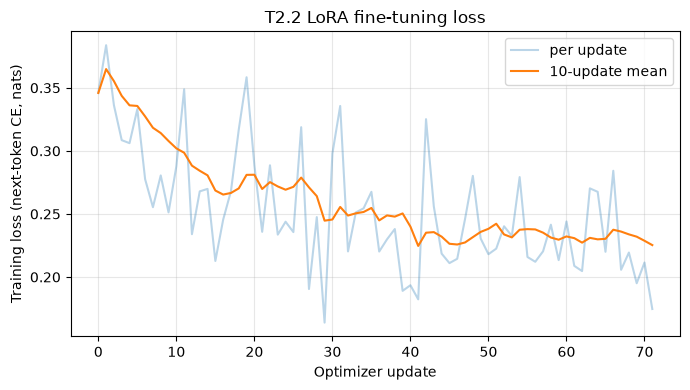

{'examples': 292,
 'lora_rank': 8,
 'lora_alpha': 16,
 'targets': ['q_proj', 'k_proj', 'v_proj', 'o_proj'],
 'optimizer': 'AdamW',
 'lr': 0.0002,
 'micro_batch': 1,
 'grad_accum': 8,
 'effective_batch': 8,
 'max_len': 384,
 'epochs': 2,
 'updates': 72,
 'trainable': 1081344,
 'trainable_pct': 0.218,
 'train_min': 4.6}

In [5]:
# ---- memory-safe settings for MPS ----
MAX_LEN = 384
MICRO, ACCUM = 1, 8            # 1 example per MPS step x 8 steps = effective batch 8
BATCH = MICRO * ACCUM
torch.mps.empty_cache()

# ---- student + LoRA ----
tok, model = load(STUDENT)
model = get_peft_model(model, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0.05,
                                         target_modules=TARGETS, task_type="CAUSAL_LM"))
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Device: {next(model.parameters()).device} | Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")


def encode(q, s):
    """Prompt + teacher solution; loss only on the solution tokens."""
    p = tok(prompt(tok, q), add_special_tokens=False).input_ids
    a = tok(s + tok.eos_token, add_special_tokens=False).input_ids
    return (p + a)[:MAX_LEN], ([-100] * len(p) + a)[:MAX_LEN]


def batchify(items):
    """Pad (ids, labels) pairs to the same length -> ids, attention mask, labels on MPS."""
    w = max(len(x) for x, _ in items)
    ids    = [x + [tok.pad_token_id] * (w - len(x)) for x, _ in items]
    mask   = [[1] * len(x) + [0] * (w - len(x)) for x, _ in items]
    labels = [y + [-100] * (w - len(y)) for _, y in items]
    return [torch.tensor(t).to(DEVICE) for t in (ids, mask, labels)]


# ---- training ----
data = [encode(q, s) for q, s in zip(train_data.question, train_data.solution)]
steps = EPOCHS * (len(data) // BATCH)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)
sched = get_cosine_schedule_with_warmup(opt, int(0.05 * steps), steps)

losses, start = [], time.time()
model.train()
for ep in range(EPOCHS):
    random.Random(SEED + ep).shuffle(data)
    for i in range(0, len(data) - BATCH + 1, BATCH):
        step_loss = 0.0
        for j in range(i, i + BATCH, MICRO):                       # small MPS steps
            ids, mask, labels = batchify(data[j:j + MICRO])
            loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss / ACCUM   # next-token CE
            loss.backward()
            step_loss += loss.item()
        opt.step(); sched.step(); opt.zero_grad()                  # 1 optimizer update
        losses.append(step_loss)
        if len(losses) <= 3 or len(losses) % 10 == 0:
            torch.mps.empty_cache()
            print(f"  epoch {ep+1} | update {len(losses)}/{steps} | loss {np.mean(losses[-10:]):.3f} | {time.time()-start:.0f}s")
train_min = (time.time() - start) / 60
model.save_pretrained(f"{OUT}/lora_adapter")
print(f"Training time: {train_min:.1f} min | updates: {len(losses)}")

# ---- loss curve ----
plt.figure(figsize=(7, 4))
plt.plot(losses, alpha=.3, label="per update")
plt.plot(pd.Series(losses).rolling(10, min_periods=1).mean(), label="10-update mean")
plt.xlabel("Optimizer update"); plt.ylabel("Training loss (next-token CE, nats)")
plt.title("T2.2 LoRA fine-tuning loss"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/t2_2_loss.png", dpi=150); plt.show()

# ---- summary for results.md ----
summary = {"examples": len(data), "lora_rank": LORA_R, "lora_alpha": LORA_ALPHA, "targets": TARGETS,
           "optimizer": "AdamW", "lr": LR, "micro_batch": MICRO, "grad_accum": ACCUM, "effective_batch": BATCH,
           "max_len": MAX_LEN, "epochs": EPOCHS, "updates": len(losses),
           "trainable": trainable, "trainable_pct": round(100 * trainable / total, 3),
           "train_min": round(train_min, 1)}
with open(f"{OUT}/t2_2_summary.json", "w") as f:
    json.dump(summary, f, indent=1)
summary

### T2.3: evaluate the original and fine-tuned students, then inspect 20 solutions

In [6]:
sets = {"GSM8K (200)": (test_q["question"], [ref(a) for a in test_q["answer"]]),
        "Synthetic (100)": ([x["question"] for x in synthetic], [float(x["answer"]) for x in synthetic])}
rows, outs = [], []
for name in ["Original", "Fine-tuned"]:
    for s, (qs, refs) in sets.items():
        print(name, s)
        if name == "Original":
            with model.disable_adapter():                     # LoRA off = original student
                gen = generate(model, tok, qs)
        else:
            gen = generate(model, tok, qs)
        ok = [same(get_answer(g), r) for g, r in zip(gen, refs)]
        rows.append({"Model": name, "Set": s, "Exact match (%)": round(100*np.mean(ok), 1), "Correct": sum(ok), "Total": len(ok)})
        outs += [{"model": name, "set": s, "question": q, "reference": r,
                  "predicted": get_answer(g), "correct": c, "output": g}
                 for q, r, g, c in zip(qs, refs, gen, ok)]

acc, outs = pd.DataFrame(rows), pd.DataFrame(outs)
acc.to_csv(f"{OUT}/t2_3_accuracy.csv", index=False); outs.to_csv(f"{OUT}/t2_3_outputs.csv", index=False)
display(acc)

# 20 solutions to inspect: same 5 questions per set for both models
idx = {s: random.Random(SEED).sample(range(len(sets[s][0])), 5) for s in sets}
sample = pd.concat([outs[(outs.model == m) & (outs.set == s)].iloc[idx[s]] for m in ["Original", "Fine-tuned"] for s in sets])
sample.assign(arithmetic_error="", reasoning_error="", right_answer_wrong_reasoning="").to_csv(f"{OUT}/t2_3_inspect.csv", index=False)
for _, r in sample.iterrows():
    print("=" * 90, f"\n[{r.model} | {r.set}] ref={r.reference} pred={r.predicted} correct={r.correct}\nQ: {r.question}\nA: {r.output}")

Original GSM8K (200)
Original Synthetic (100)
Fine-tuned GSM8K (200)
Fine-tuned Synthetic (100)


,Model,Set,Exact match (%),Correct,Total
0,Original,GSM8K (200),37.0,74,200
1,Original,Synthetic (100),63.0,63,100
2,Fine-tuned,GSM8K (200),38.5,77,200
3,Fine-tuned,Synthetic (100),54.0,54,100


[Original | GSM8K (200)] ref=85.0 pred=85.0 correct=True
Q: Maggie spent a quarter of her money, while Riza spent one-third of her money. They each had $60. How much money do the two of them have left?
A: To determine how much money Maggie and Riza have left after their expenditures, we will follow these steps:

1. **Calculate Maggie's total expenditure:**
   - Maggie spent a quarter of her money.
   - Since she has $60, we calculate:
     \[
     \text{Maggie's expenditure} = \frac{1}{4} \times 60 = 15
     \]

2. **Calculate Riza's total expenditure:**
   - Riza spent one-third of her money.
   - Since she also has $60, we calculate:
     \[
     \text{Riza's expenditure} = \frac{1}{3} \times 60 = 20
     \]

3. **Determine the remaining amount for each person:**
   - Subtract the amounts spent from their initial amount to find out how much they have left.
   - For Maggie:
     \[
     \text{Maggie's remaining} = 60 - 15 = 45
     \]
   - For Riza:
     \[
     \text{Riza's remaining

## T2.3(b) · Manual Inspection of 20 Generated Solutions

The assignment asks us to inspect 20 generated solutions from both evaluation sets for **arithmetic and reasoning errors**, and to check whether a model ever reached the **correct answer through incorrect reasoning**.

The 20 solutions are the same 5 questions per evaluation set for both models:

| Rows | Model | Evaluation set |
|---|---|---|
| 1–5 | Original | GSM8K test |
| 6–10 | Original | Synthetic |
| 11–15 | Fine-tuned (LoRA) | GSM8K test |
| 16–20 | Fine-tuned (LoRA) | Synthetic |

For each solution we record:
- **arithmetic_error**: a calculation is wrong (e.g. 49 − 12 = 37)
- **reasoning_error**: the steps or the setup are wrong, even if each calculation is right
- **right_answer_wrong_reasoning**: the final answer is correct, but the reasoning is wrong or imprecise
- **truncated**: the output hit the token limit before the final `#### <number>` line
- **note**: a short description of the problem

The notes were drafted with the help of an AI tool (Claude) and then reviewed and confirmed manually.

In [7]:
# ---- T2.3(b): manual inspection notes for the 20 sampled solutions ----
# Order = same as printed by Cell 6: Original GSM8K (5), Original Synthetic (5),
#                                    Fine-tuned GSM8K (5), Fine-tuned Synthetic (5)
# Columns: arithmetic_error, reasoning_error, right_answer_wrong_reasoning, truncated, note
notes = [
    # ---------- Original | GSM8K ----------
    ("no",  "no",  "no",  "yes", "Correct steps; cut off before '####', answer taken from last number"),
    ("no",  "yes", "no",  "no",  "Treats $10 as price per bagel (36 x $10) instead of per pack"),
    ("yes", "yes", "no",  "yes", "Writes 'stolen = 49 - 12 = 37'; invents a third theft; cut off"),
    ("no",  "yes", "no",  "no",  "Misreads '4 yogurts for $5' as 4 packs per day"),
    ("no",  "yes", "no",  "yes", "Wrong day count (362 days); cut off before final answer"),
    # ---------- Original | Synthetic ----------
    ("no",  "no",  "no",  "no",  "Correct"),
    ("no",  "no",  "no",  "no",  "Correct"),
    ("no",  "no",  "no",  "no",  "Correct"),
    ("no",  "no",  "no",  "yes", "Correct steps but cut off before final subtraction; extracted 36"),
    ("no",  "yes", "no",  "no",  "Takes 1/3 of the plants instead of 1/3 of the tomatoes"),
    # ---------- Fine-tuned | GSM8K ----------
    ("no",  "yes", "no",  "no",  "Misreads '$60 each' and sets up a wrong equation (M = 240)"),
    ("no",  "yes", "yes", "no",  "Right answer via rounding: 10/9 ~ 1.11 x 0.9 = 0.999 -> 1.00 (exact: $36/36)"),
    ("no",  "yes", "no",  "no",  "Adds the stolen bananas back to the pile (48 + 24)"),
    ("no",  "yes", "no",  "no",  "Invents '$5 for 5 packs' and divides days by 4"),
    ("no",  "yes", "no",  "no",  "Nonsensical date logic; '999 days'"),
    # ---------- Fine-tuned | Synthetic ----------
    ("no",  "no",  "no",  "no",  "Correct"),
    ("no",  "yes", "no",  "no",  "Invents $12 each for lemons, sugar and cups (hallucinated costs)"),
    ("no",  "no",  "no",  "no",  "Correct"),
    ("no",  "no",  "no",  "yes", "Correct steps but cut off before the final answer"),
    ("no",  "no",  "no",  "no",  "Correct; fixes the original model's 1/3-of-plants mistake"),
]

inspect = pd.read_csv(f"{OUT}/t2_3_inspect.csv")
assert len(inspect) == len(notes) == 20, f"expected 20 rows, found {len(inspect)}"
cols = ["arithmetic_error", "reasoning_error", "right_answer_wrong_reasoning", "truncated", "note"]
inspect[cols] = pd.DataFrame(notes, columns=cols)
inspect.to_csv(f"{OUT}/t2_3_inspect.csv", index=False)

# ---- summary of the inspection ----
summary_insp = (inspect.assign(**{c: inspect[c].eq("yes") for c in cols[:4]})
                .groupby("model")[["correct"] + cols[:4]].sum().astype(int))
                
summary_insp.columns = ["Correct", "Arithmetic errors", "Reasoning errors",
                        "Right answer, wrong reasoning", "Truncated (no ####)"]
display(inspect[["model", "set", "reference", "predicted", "correct"] + cols])
display(summary_insp)

,model,set,reference,predicted,correct,arithmetic_error,reasoning_error,right_answer_wrong_reasoning,truncated,note
0,Original,GSM8K (200),85.0,85.0,True,no,no,no,yes,"Correct steps; cut off before '####', answer t..."
1,Original,GSM8K (200),1.0,324.0,False,no,yes,no,no,Treats $10 as price per bagel (36 x $10) inste...
2,Original,GSM8K (200),43.0,12.0,False,yes,yes,no,yes,Writes 'stolen = 49 - 12 = 37'; invents a thir...
3,Original,GSM8K (200),75.0,600.0,False,no,yes,no,no,Misreads '4 yogurts for $5' as 4 packs per day
4,Original,GSM8K (200),525.0,105000.0,False,no,yes,no,yes,Wrong day count (362 days); cut off before fin...
5,Original,Synthetic (100),160.0,160.0,True,no,no,no,no,Correct
6,Original,Synthetic (100),24.0,24.0,True,no,no,no,no,Correct
7,Original,Synthetic (100),250.0,250.0,True,no,no,no,no,Correct
8,Original,Synthetic (100),12.0,36.0,False,no,no,no,yes,Correct steps but cut off before final subtrac...
9,Original,Synthetic (100),504.0,728.0,False,no,yes,no,no,Takes 1/3 of the plants instead of 1/3 of the ...


,Correct,Arithmetic errors,Reasoning errors,"Right answer, wrong reasoning",Truncated (no ####)
model,,,,,
Fine-tuned,4,0,6,1,1
Original,4,1,5,0,4


# Task 3: DARTS on CIFAR-10
## T3.1 · Differentiable Cell
Supernet: 3x3 stem (16 ch) → 2 searchable cells (own weights, shared α) → GAP → 10-class head.
Each cell: 4 nodes, 6 edges (i<j); each edge mixes 5 ops {none, skip, conv1x1, conv3x3, avgpool3x3} with softmax(α).

### 3.1‑a · Imports and settings

In [8]:
import os, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

SEED = 42
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
OUT = "task3_outputs"; os.makedirs(OUT, exist_ok=True)

C, BATCH = 16, 64
SEARCH_EPOCHS, TRAIN_EPOCHS = 3, 5
W_LR, W_MOMENTUM, W_DECAY = 0.025, 0.9, 3e-4     # weights w: SGD + cosine
ARCH_LR, ARCH_DECAY = 3e-3, 1e-3                 # alpha: Adam

OPS   = ["none", "skip", "conv1x1", "conv3x3", "avgpool3x3"]
EDGES = [(0, 1), (0, 2), (1, 2), (0, 3), (1, 3), (2, 3)]

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def sync():
    if DEVICE.type == "mps": torch.mps.synchronize()

set_seed(); print("Device:", DEVICE)

Device: mps


### 3.1‑b · Data: 5,000 train and 1,000 val, stratified, from the CIFAR‑10 training split

In [11]:
ds = torchvision.datasets.CIFAR10(root="data", train=True, download=True)
labels = np.array(ds.targets)
rng = np.random.RandomState(SEED)
train_idx, val_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(labels == c)[0])
    train_idx += list(idx[:500]); val_idx += list(idx[500:600])

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)
def to_tensor(idx):
    x = torch.tensor(ds.data[idx]).permute(0, 3, 1, 2).float() / 255
    return ((x - mean) / std).to(DEVICE)

Xtr, ytr = to_tensor(train_idx), torch.tensor(labels[train_idx]).to(DEVICE)
Xva, yva = to_tensor(val_idx),   torch.tensor(labels[val_idx]).to(DEVICE)
print("Train:", tuple(Xtr.shape), "| Val:", tuple(Xva.shape))

100%|██████████| 170M/170M [21:32<00:00, 132kB/s]    


Train: (5000, 3, 32, 32) | Val: (1000, 3, 32, 32)


### 3.1‑c · Operations, mixed edge, cell and two-cell supernet

In [12]:
class Zero(nn.Module):
    def forward(self, x): return x * 0.0

def make_op(name, C):
    """All ops keep shape (B, C, 32, 32)."""
    if name == "none":       return Zero()
    if name == "skip":       return nn.Identity()
    if name == "conv1x1":    return nn.Sequential(nn.ReLU(), nn.Conv2d(C, C, 1, bias=False), nn.BatchNorm2d(C, affine=False))
    if name == "conv3x3":    return nn.Sequential(nn.ReLU(), nn.Conv2d(C, C, 3, padding=1, bias=False), nn.BatchNorm2d(C, affine=False))
    if name == "avgpool3x3": return nn.AvgPool2d(3, stride=1, padding=1, count_include_pad=False)


class MixedEdge(nn.Module):
    """o_bar(x) = sum_o p_o * o(x)"""
    def __init__(self, C):
        super().__init__()
        self.ops = nn.ModuleList(make_op(o, C) for o in OPS)
    def forward(self, x, p):
        return sum(w * op(x) for w, op in zip(p, self.ops))


class SearchCell(nn.Module):
    """x_j = sum_{i<j} o_bar_(i,j)(x_i); cell output = x_3."""
    def __init__(self, C):
        super().__init__()
        self.edges = nn.ModuleList(MixedEdge(C) for _ in EDGES)
    def forward(self, x, probs):
        nodes = [x]
        for j in range(1, 4):
            nodes.append(sum(self.edges[e](nodes[i], probs[e]) for e, (i, jj) in enumerate(EDGES) if jj == j))
        return nodes[3]


class Supernet(nn.Module):
    def __init__(self, C=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, C, 3, padding=1, bias=False), nn.BatchNorm2d(C))
        self.cells = nn.ModuleList([SearchCell(C), SearchCell(C)])           # separate op weights
        self.alpha = nn.Parameter(1e-3 * torch.randn(len(EDGES), len(OPS)))  # 6 x 5, shared
        self.head = nn.Linear(C, 10)
    def probs(self):
        return F.softmax(self.alpha, dim=-1)
    def weight_params(self):
        return [p for n, p in self.named_parameters() if n != "alpha"]
    def forward(self, x):
        p, x = self.probs(), self.stem(x)
        for cell in self.cells:
            x = cell(x, p)
        return self.head(x.mean(dim=(2, 3)))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def draw_cell(edge_labels, title, path):
    pos = {0: (0, 0), 1: (1, 1), 2: (1, -1), 3: (2, 0)}
    fig, ax = plt.subplots(figsize=(6, 4))
    for e, label in edge_labels.items():
        i, j = EDGES[e]
        ax.annotate("", xy=pos[j], xytext=pos[i],
                    arrowprops=dict(arrowstyle="->", lw=1.5, shrinkA=15, shrinkB=15, connectionstyle="arc3,rad=0.15"))
        ax.text((pos[i][0] + pos[j][0]) / 2, (pos[i][1] + pos[j][1]) / 2 + 0.08, f"{i}->{j}: {label}",
                ha="center", fontsize=8, bbox=dict(boxstyle="round", fc="lightyellow"))
    for n, (x, y) in pos.items():
        ax.add_patch(plt.Circle((x, y), 0.13, color="tab:blue"))
        ax.text(x, y, str(n), color="white", ha="center", va="center", fontsize=12, weight="bold")
    ax.set_xlim(-0.4, 2.4); ax.set_ylim(-1.4, 1.4); ax.axis("off"); ax.set_title(title)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

### 3.1‑d · Verification

input (8, 3, 32, 32) | stem (8, 16, 32, 32) | cell (8, 16, 32, 32) | logits (8, 10)
alpha shape: (6, 5) (6 edges x 5 ops, shared by both cells)
weight params: 31,354 | alpha params: 30
backward OK | loss 2.6057 | alpha grad norm 5.99e-02 | weights with grad: 29/29
prob sum per edge: [1. 1. 1. 1. 1. 1.]
edge 0->1 output change 0.3705 | logits change 0.0691 | op weights unchanged: True


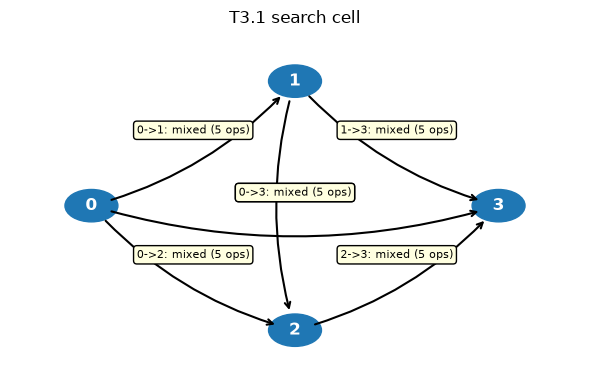

In [13]:
set_seed()
net = Supernet(C).to(DEVICE)
x, y = Xtr[:8], ytr[:8]

# 1) output dimensions
with torch.no_grad():
    h = net.stem(x); cell_out = net.cells[0](h, net.probs()); logits = net(x)
print("input", tuple(x.shape), "| stem", tuple(h.shape), "| cell", tuple(cell_out.shape), "| logits", tuple(logits.shape))
print("alpha shape:", tuple(net.alpha.shape), "(6 edges x 5 ops, shared by both cells)")
print(f"weight params: {sum(p.numel() for p in net.weight_params()):,} | alpha params: {net.alpha.numel()}")

# 2) forward + backward
net.train(); net.zero_grad()
loss = F.cross_entropy(net(x), y); loss.backward()
print(f"backward OK | loss {loss.item():.4f} | alpha grad norm {net.alpha.grad.norm():.2e} | "
      f"weights with grad: {sum(p.grad is not None for p in net.weight_params())}/{len(net.weight_params())}")

# 3) probabilities sum to one on every edge
print("prob sum per edge:", net.probs().sum(1).detach().cpu().numpy().round(6))

# 4) change alpha, keep op weights fixed -> mixed output changes
net.eval()
with torch.no_grad():
    w_before = [p.clone() for p in net.weight_params()]
    alpha_saved = net.alpha.clone()
    edge_a, out_a = net.cells[0].edges[0](h, net.probs()[0]), net(x)
    net.alpha[0] = torch.tensor([0., 0., 0., 5., 0.], device=DEVICE)     # edge 0->1 now prefers conv3x3
    edge_b, out_b = net.cells[0].edges[0](h, net.probs()[0]), net(x)
    same_w = all(torch.equal(a, b) for a, b in zip(w_before, net.weight_params()))
    net.alpha.copy_(alpha_saved)
print(f"edge 0->1 output change {(edge_b - edge_a).abs().mean():.4f} | logits change {(out_b - out_a).abs().mean():.4f} | "
      f"op weights unchanged: {same_w}")

draw_cell({e: "mixed (5 ops)" for e in range(6)}, "T3.1 search cell", f"{OUT}/t3_1_cell.png")

## T3.2 · First-Order Search
Two optimizers, alternating every step:
- **α** (Adam) updated on a **validation** batch, with w fixed.
- **w** (SGD) updated on a **training** batch, with α fixed.
Search for 3 epochs; record losses, accuracy and α probabilities; verify each optimizer updates only its own parameters.

In [14]:
@torch.no_grad()
def evaluate(model, X, y, bs=500):
    model.eval(); loss = correct = 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), 100 * correct / len(X)
def search(model, epochs):
    w_opt = torch.optim.SGD(model.weight_params(), lr=W_LR, momentum=W_MOMENTUM, weight_decay=W_DECAY)
    a_opt = torch.optim.Adam([model.alpha], lr=ARCH_LR, betas=(0.5, 0.999), weight_decay=ARCH_DECAY)
    steps = len(Xtr) // BATCH
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(w_opt, epochs * steps)
    hist, step_log, probs_hist, check, n_upd = [], [], [model.probs().detach().cpu().numpy()], {}, 0

    for epoch in range(1, epochs + 1):
        model.train()
        perm_t, perm_v = torch.randperm(len(Xtr)), torch.randperm(len(Xva))
        t_loss = t_correct = 0
        for s in range(steps):
            it = perm_t[s * BATCH:(s + 1) * BATCH]
            iv = perm_v[torch.arange(s * BATCH, (s + 1) * BATCH) % len(Xva)]
            first = (epoch == 1 and s == 0)
            if first: w0, a0 = [p.clone() for p in model.weight_params()], model.alpha.clone()

            # 1) alpha step on VALIDATION data (w fixed: gradient only w.r.t. alpha)
            v_loss = F.cross_entropy(model(Xva[iv]), yva[iv])
            model.alpha.grad = torch.autograd.grad(v_loss, [model.alpha])[0]
            a_opt.step()
            if first:
                check["alpha step -> alpha changed"] = not torch.equal(a0, model.alpha)
                check["alpha step -> weight tensors changed"] = sum(not torch.equal(a, b) for a, b in zip(w0, model.weight_params()))
                w1, a1 = [p.clone() for p in model.weight_params()], model.alpha.clone()

            # 2) weight step on TRAINING data (alpha not in w_opt)
            w_opt.zero_grad()
            out = model(Xtr[it]); loss = F.cross_entropy(out, ytr[it]); loss.backward()
            nn.utils.clip_grad_norm_(model.weight_params(), 5.0)
            w_opt.step(); sched.step(); n_upd += 1
            if first:
                check["weight step -> alpha changed"] = not torch.equal(a1, model.alpha)
                check["weight step -> weight tensors changed"] = sum(not torch.equal(a, b) for a, b in zip(w1, model.weight_params()))
                check["total weight tensors"] = len(w1)

            t_loss += loss.item() * len(it); t_correct += (out.argmax(1) == ytr[it]).sum().item()
            step_log.append({"step": n_upd, "train_loss": loss.item(), "val_loss": v_loss.item()})
            probs_hist.append(model.probs().detach().cpu().numpy())

        vl, va = evaluate(model, Xva, yva)
        hist.append({"epoch": epoch, "train_loss": t_loss / (steps * BATCH), "train_acc": 100 * t_correct / (steps * BATCH),
                     "val_loss": vl, "val_acc": va})
        print(hist[-1])
    return pd.DataFrame(hist), pd.DataFrame(step_log), np.array(probs_hist), check, n_upd


set_seed()
supernet = Supernet(C).to(DEVICE)
t0 = time.time()
hist, step_log, probs_hist, check, n_upd = search(supernet, SEARCH_EPOCHS)
search_min = (time.time() - t0) / 60
print(f"\nsearch time {search_min:.1f} min | {n_upd} weight updates + {n_upd} alpha updates")
print("Parameter-update verification (first step):")
for k, v in check.items(): print(f"  {k}: {v}")
hist.to_csv(f"{OUT}/t3_2_history.csv", index=False)

{'epoch': 1, 'train_loss': 2.0686536660561194, 'train_acc': 22.516025641025642, 'val_loss': 1.9667894897460938, 'val_acc': 25.1}
{'epoch': 2, 'train_loss': 1.8590495097331512, 'train_acc': 30.068108974358974, 'val_loss': 1.8315699462890624, 'val_acc': 32.0}
{'epoch': 3, 'train_loss': 1.7663988501597674, 'train_acc': 33.79407051282051, 'val_loss': 1.7793301391601561, 'val_acc': 32.5}

search time 0.3 min | 234 weight updates + 234 alpha updates
Parameter-update verification (first step):
  alpha step -> alpha changed: True
  alpha step -> weight tensors changed: 0
  weight step -> alpha changed: False
  weight step -> weight tensors changed: 29
  total weight tensors: 29


### 3.2‑c · Training curves and probability histories

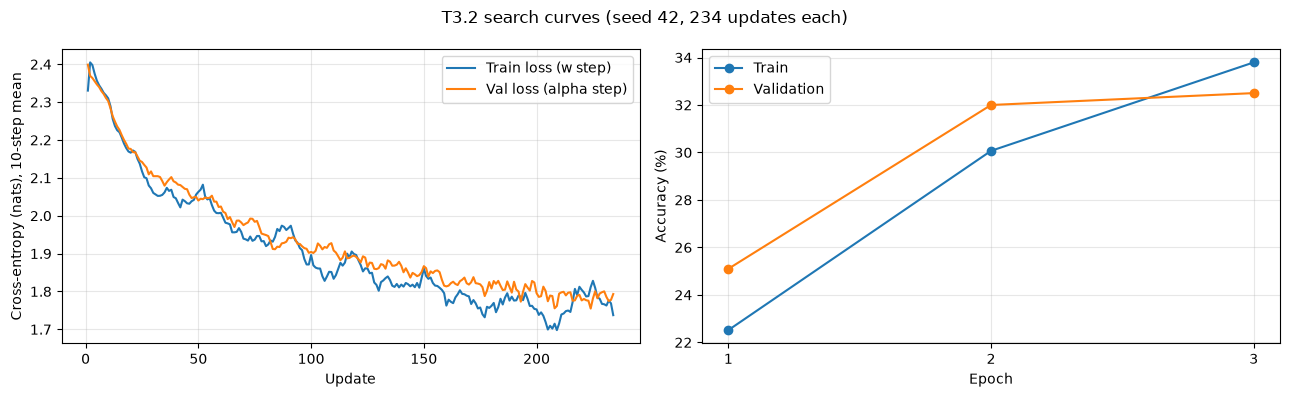

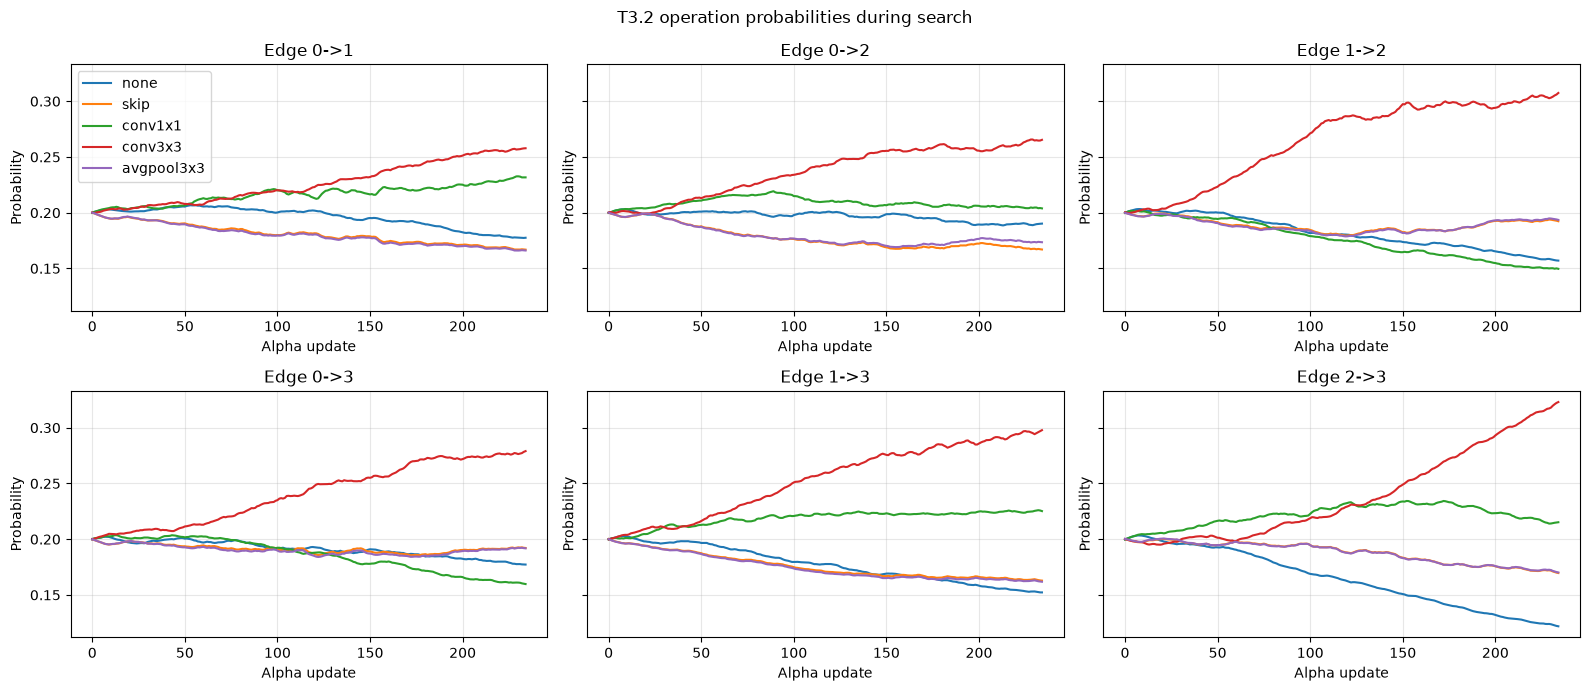

Final probabilities:


,none,skip,conv1x1,conv3x3,avgpool3x3
0->1,0.178,0.167,0.232,0.258,0.166
0->2,0.190,0.167,0.204,0.265,0.174
1->2,0.157,0.192,0.150,0.307,0.194
0->3,0.177,0.192,0.160,0.279,0.192
1->3,0.152,0.163,0.225,0.298,0.162
2->3,0.122,0.170,0.215,0.323,0.170


Change (final - start):


,none,skip,conv1x1,conv3x3,avgpool3x3
0->1,-0.022,-0.033,0.032,0.058,-0.034
0->2,-0.010,-0.033,0.004,0.065,-0.027
1->2,-0.043,-0.008,-0.050,0.107,-0.006
0->3,-0.022,-0.008,-0.040,0.079,-0.008
1->3,-0.048,-0.037,0.025,0.098,-0.038
2->3,-0.078,-0.030,0.015,0.123,-0.030


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(step_log.step, step_log.train_loss.rolling(10, min_periods=1).mean(), label="Train loss (w step)")
ax[0].plot(step_log.step, step_log.val_loss.rolling(10, min_periods=1).mean(), label="Val loss (alpha step)")
ax[0].set_xlabel("Update"); ax[0].set_ylabel("Cross-entropy (nats), 10-step mean"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.epoch, hist.train_acc, "o-", label="Train"); ax[1].plot(hist.epoch, hist.val_acc, "o-", label="Validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_xticks(hist.epoch); ax[1].legend(); ax[1].grid(alpha=.3)
plt.suptitle(f"T3.2 search curves (seed {SEED}, {n_upd} updates each)"); plt.tight_layout()
plt.savefig(f"{OUT}/t3_2_curves.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)
for e, ax in enumerate(axes.flat):
    for o, name in enumerate(OPS):
        ax.plot(probs_hist[:, e, o], label=name)
    ax.set_title(f"Edge {EDGES[e][0]}->{EDGES[e][1]}"); ax.set_xlabel("Alpha update"); ax.set_ylabel("Probability"); ax.grid(alpha=.3)
axes[0, 0].legend()
plt.suptitle("T3.2 operation probabilities during search"); plt.tight_layout()
plt.savefig(f"{OUT}/t3_2_probabilities.png", dpi=150); plt.show()

idx = [f"{i}->{j}" for i, j in EDGES]
print("Final probabilities:");    display(pd.DataFrame(probs_hist[-1], columns=OPS, index=idx).round(3))
print("Change (final - start):");  display(pd.DataFrame(probs_hist[-1] - probs_hist[0], columns=OPS, index=idx).round(3))

## T3.3 · Extract and Evaluate a Discrete Architecture
Per node keep the 2 strongest incoming edges (ranked by best non-`none` probability) → 5 edges, one op each.
Compare: continuous supernet vs discrete model with inherited weights (same checkpoint, no fine-tuning) vs discrete model trained from scratch for 5 epochs.

### 3.3‑a · Discrete network and extraction



Kept edges: 5
Architecture encoding (from, to, op): [(0, 1, 'conv3x3'), (0, 2, 'conv3x3'), (1, 2, 'conv3x3'), (1, 3, 'conv3x3'), (2, 3, 'conv3x3')]


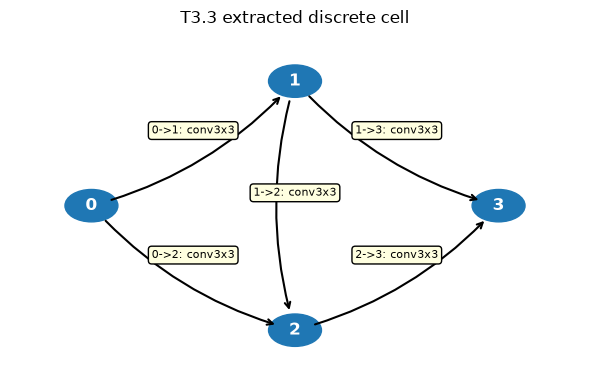

In [16]:
class DiscreteCell(nn.Module):
    def __init__(self, C, genotype):
        super().__init__()
        self.genotype = genotype                                           # [(edge_index, op_name), ...]
        self.ops = nn.ModuleDict({str(e): make_op(o, C) for e, o in genotype})
    def forward(self, x):
        nodes = [x]
        for j in range(1, 4):
            nodes.append(sum(self.ops[str(e)](nodes[EDGES[e][0]]) for e, _ in self.genotype if EDGES[e][1] == j))
        return nodes[3]


class DiscreteNet(nn.Module):
    def __init__(self, genotype, C=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, C, 3, padding=1, bias=False), nn.BatchNorm2d(C))
        self.cells = nn.ModuleList([DiscreteCell(C, genotype), DiscreteCell(C, genotype)])
        self.head = nn.Linear(C, 10)
    def forward(self, x):
        x = self.stem(x)
        for cell in self.cells:
            x = cell(x)
        return self.head(x.mean(dim=(2, 3)))


def extract(probs):
    genotype = []
    for j in range(1, 4):
        incoming = [e for e, (i, jj) in enumerate(EDGES) if jj == j]
        keep = sorted(incoming, key=lambda e: -probs[e, 1:].max().item())[:2]
        genotype += [(e, OPS[1 + probs[e, 1:].argmax().item()]) for e in sorted(keep)]
    return genotype


genotype = extract(supernet.probs().detach().cpu())
encoding = [(EDGES[e][0], EDGES[e][1], o) for e, o in genotype]
print("Kept edges:", len(genotype))
print("Architecture encoding (from, to, op):", encoding)
draw_cell({e: o for e, o in genotype}, "T3.3 extracted discrete cell", f"{OUT}/t3_3_discrete_cell.png")

### 3.3‑b · Same checkpoint: supernet vs inherited weights (no fine-tuning)

In [17]:
torch.save(supernet.state_dict(), f"{OUT}/supernet.pt")
ckpt = torch.load(f"{OUT}/supernet.pt")

sn = Supernet(C).to(DEVICE); sn.load_state_dict(ckpt)
sn_loss, sn_acc = evaluate(sn, Xva, yva)

def inherit(discrete, supernet):
    discrete.stem.load_state_dict(supernet.stem.state_dict())
    discrete.head.load_state_dict(supernet.head.state_dict())
    for dc, sc in zip(discrete.cells, supernet.cells):
        for e, o in dc.genotype:
            dc.ops[str(e)].load_state_dict(sc.edges[e].ops[OPS.index(o)].state_dict())

inherited = DiscreteNet(genotype, C).to(DEVICE); inherit(inherited, sn)
inh_loss, inh_acc = evaluate(inherited, Xva, yva)
print(f"Continuous supernet : {sn_acc:.2f}% (loss {sn_loss:.3f})")
print(f"Inherited discrete  : {inh_acc:.2f}% (loss {inh_loss:.3f})")

Continuous supernet : 32.50% (loss 1.779)
Inherited discrete  : 12.10% (loss 69.117)


### 3.3‑c · Train from scratch (5 epochs) and comparison table

{'epoch': 1, 'val_loss': 1.995733642578125, 'val_acc': 25.7}
{'epoch': 2, 'val_loss': 1.7214517211914062, 'val_acc': 37.1}
{'epoch': 3, 'val_loss': 1.6458092041015624, 'val_acc': 38.3}
{'epoch': 4, 'val_loss': 1.5212183837890625, 'val_acc': 45.2}
{'epoch': 5, 'val_loss': 1.4879882202148438, 'val_acc': 46.9}


,Model,Val acc (%) [measured],Params [analytical],MACs (M) [analytical],Size FP32 (KB) [analytical],Median latency (ms) [measured],Weight updates
0,Continuous supernet,32.5,31384,31.90,122.6,3.838,234
1,"Discrete, inherited weights",12.1,23674,24.04,92.5,1.339,234
2,"Discrete, trained from scratch",46.9,23674,24.04,92.5,1.266,390


search 0.3 min | scratch training 0.1 min


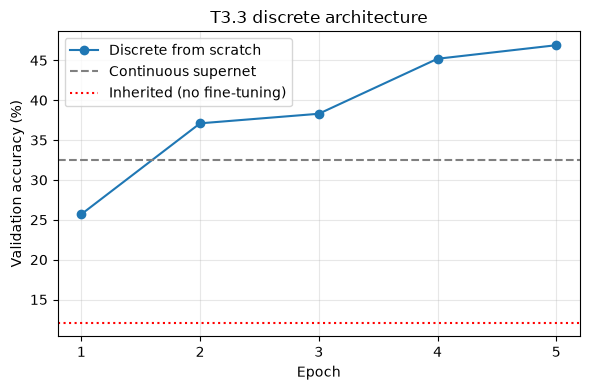

In [18]:
@torch.inference_mode()
def latency_ms(model, warmup=10, runs=20):
    model.eval(); x = torch.randn(1, 3, 32, 32, device=DEVICE)
    for _ in range(warmup): model(x)
    times = []
    for _ in range(runs):
        sync(); t0 = time.perf_counter(); model(x); sync()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


@torch.no_grad()
def count_macs(model):
    macs = 0
    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += out[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        else:
            macs += m.in_features * m.out_features
    hooks = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval(); model(torch.randn(1, 3, 32, 32, device=DEVICE))
    for h in hooks: h.remove()
    return macs


def train_discrete(model, epochs):
    opt = torch.optim.SGD(model.parameters(), lr=W_LR, momentum=W_MOMENTUM, weight_decay=W_DECAY)
    steps = len(Xtr) // BATCH
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * steps)
    hist, n = [], 0
    for epoch in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(Xtr))
        for s in range(steps):
            idx = perm[s * BATCH:(s + 1) * BATCH]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); sched.step(); n += 1
        vl, va = evaluate(model, Xva, yva)
        hist.append({"epoch": epoch, "val_loss": vl, "val_acc": va}); print(hist[-1])
    return pd.DataFrame(hist), n


set_seed()
scratch = DiscreteNet(genotype, C).to(DEVICE)
t0 = time.time()
hist_s, n_scratch = train_discrete(scratch, TRAIN_EPOCHS)
scratch_min = (time.time() - t0) / 60
torch.save(scratch.state_dict(), f"{OUT}/discrete_scratch.pt")

rows = []
for name, m, acc, upd in [("Continuous supernet", sn, sn_acc, n_upd),
                          ("Discrete, inherited weights", inherited, inh_acc, n_upd),
                          ("Discrete, trained from scratch", scratch, hist_s.val_acc.iloc[-1], n_scratch)]:
    p = count_params(m)
    rows.append({"Model": name, "Val acc (%) [measured]": round(acc, 2), "Params [analytical]": p,
                 "MACs (M) [analytical]": round(count_macs(m) / 1e6, 2),
                 "Size FP32 (KB) [analytical]": round(p * 4 / 1024, 1),
                 "Median latency (ms) [measured]": round(latency_ms(m), 3), "Weight updates": upd})
table = pd.DataFrame(rows); table.to_csv(f"{OUT}/t3_3_comparison.csv", index=False)
display(table)
print(f"search {search_min:.1f} min | scratch training {scratch_min:.1f} min")

plt.figure(figsize=(6, 4))
plt.plot(hist_s.epoch, hist_s.val_acc, "o-", label="Discrete from scratch")
plt.axhline(sn_acc, ls="--", c="gray", label="Continuous supernet")
plt.axhline(inh_acc, ls=":", c="red", label="Inherited (no fine-tuning)")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy (%)"); plt.xticks(hist_s.epoch)
plt.title("T3.3 discrete architecture"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/t3_3_scratch_curve.png", dpi=150); plt.show()

# T4 · Supernet and Path Sampling


### 4.1‑a · Settings and data

In [28]:
import os, time, copy, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

SEED, C, N_BLOCKS, BATCH = 42, 16, 4, 64
EPOCHS, LR, WD = 5, 2e-3, 1e-4          # AdamW for supernet and from-scratch training
ADAPT_LR, N_SUBNETS = 5e-4, 12          # AdamW for T4.3 adaptation                       # T4.3 adaptation
OPS = ["conv3x3", "conv5x5", "dwsep3x3", "identity"]
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
OUT = "task4_outputs"; os.makedirs(OUT, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

# Fixed stratified subset: 500 train + 100 val per class from the CIFAR-10 training split
ds = torchvision.datasets.CIFAR10(root="data", train=True, download=True)
labels, rng = np.array(ds.targets), np.random.RandomState(SEED)
tr_idx, va_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(labels == c)[0]); tr_idx += list(idx[:500]); va_idx += list(idx[500:600])
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1); std = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)
prep = lambda i: ((torch.tensor(ds.data[i]).permute(0, 3, 1, 2).float() / 255 - mean) / std).to(DEVICE)
Xtr, ytr = prep(tr_idx), torch.tensor(labels[tr_idx]).to(DEVICE)
Xva, yva = prep(va_idx), torch.tensor(labels[va_idx]).to(DEVICE)
print("Device:", DEVICE, "| Train:", tuple(Xtr.shape), "| Val:", tuple(Xva.shape))

Device: mps | Train: (5000, 3, 32, 32) | Val: (1000, 3, 32, 32)


### 4.1‑b · Operations, supernet, sampling and extraction

In [29]:
def make_op(name):
    """All ops keep (B, 16, 32, 32). GroupNorm instead of BatchNorm."""
    if name == "identity":
        return nn.Identity()
    if name == "dwsep3x3":
        convs = [nn.Conv2d(C, C, 3, padding=1, groups=C, bias=False), nn.Conv2d(C, C, 1, bias=False)]
    else:
        k = 3 if name == "conv3x3" else 5
        convs = [nn.Conv2d(C, C, k, padding=k // 2, bias=False)]
    return nn.Sequential(*convs, nn.GroupNorm(4, C), nn.ReLU())


class Supernet(nn.Module):
    """Stem -> 4 blocks (each holds all 4 ops) -> GAP -> head. Only the path's ops are executed."""
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, C, 3, padding=1, bias=False), nn.GroupNorm(4, C), nn.ReLU())
        self.blocks = nn.ModuleList(nn.ModuleList(make_op(o) for o in OPS) for _ in range(N_BLOCKS))
        self.head = nn.Linear(C, 10)
    def forward(self, x, path):
        x = self.stem(x)
        for block, op in zip(self.blocks, path):
            x = block[op](x)
        return self.head(x.mean(dim=(2, 3)))


class SubNet(nn.Module):
    """Standalone network for one path (copies the chosen weights from a supernet)."""
    def __init__(self, supernet, path):
        super().__init__()
        self.path = tuple(path)
        self.stem = copy.deepcopy(supernet.stem)
        self.blocks = nn.Sequential(*[copy.deepcopy(supernet.blocks[b][op]) for b, op in enumerate(path)])
        self.head = copy.deepcopy(supernet.head)
    def forward(self, x):
        return self.head(self.blocks(self.stem(x)).mean(dim=(2, 3)))


def sample_path(rng):                       # uniform: each block picks one of 4 ops
    return tuple(rng.randrange(len(OPS)) for _ in range(N_BLOCKS))

def path_name(path):
    return "-".join(OPS[o] for o in path)

def active_params(net, path):               # supernet parameter names used by a path
    return [n for n, _ in net.named_parameters()
            if n.startswith(("stem", "head")) or any(n.startswith(f"blocks.{b}.{op}.") for b, op in enumerate(path))]

def count_params(m):
    return sum(p.numel() for p in m.parameters())

@torch.no_grad()
def evaluate(fn, bs=500):                   # fn = callable model; GroupNorm has no running stats
    loss = correct = 0
    for i in range(0, len(Xva), bs):
        out = fn(Xva[i:i + bs])
        loss += F.cross_entropy(out, yva[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == yva[i:i + bs]).sum().item()
    return loss / len(Xva), 100 * correct / len(Xva)

### 4.1‑c · Verification: two example paths, shared weights, identity has no parameters

In [30]:
set_seed()
net = Supernet().to(DEVICE)
rng = random.Random(SEED)
pA = sample_path(rng)
while True:                                 # pick a second path that shares some ops and differs in others
    pB = sample_path(rng)
    same = sum(a == b for a, b in zip(pA, pB))
    if 0 < same < N_BLOCKS: break

x = Xtr[:4]
for tag, p in [("A", pA), ("B", pB)]:
    sub = SubNet(net, p).to(DEVICE)
    with torch.no_grad():
        out_super, out_sub = net(x, p), sub(x)
    print(f"Path {tag} {p} = {path_name(p)}")
    print(f"  output shape {tuple(out_sub.shape)} | extracted subnet == supernet path: {torch.allclose(out_super, out_sub)} "
          f"| params {count_params(sub):,}")

mapping = pd.DataFrame([{"block": b, "path A op": OPS[pA[b]], "path B op": OPS[pB[b]],
                         "A params": count_params(net.blocks[b][pA[b]]), "B params": count_params(net.blocks[b][pB[b]]),
                         "shared weights": pA[b] == pB[b]} for b in range(N_BLOCKS)])
display(mapping)

shared = set(active_params(net, pA)) & set(active_params(net, pB))
print(f"Shared parameter tensors: {len(shared)} -> stem, head and blocks where both paths use the same op")
print(f"Shared parameter count: {sum(dict(net.named_parameters())[n].numel() for n in shared):,}")
print("Parameters per op:", {o: count_params(make_op(o)) for o in OPS})
print("Identity op has conv params:", any(isinstance(m, nn.Conv2d) for m in net.blocks[0][3].modules()),
      "| identity params:", count_params(net.blocks[0][3]))
print(f"Supernet params: {count_params(net):,} | search space size: {len(OPS)}^{N_BLOCKS} = {len(OPS)**N_BLOCKS}")

Path A (0, 0, 2, 1) = conv3x3-conv3x3-dwsep3x3-conv5x5
  output shape (4, 10) | extracted subnet == supernet path: True | params 12,170
Path B (3, 0, 0, 0) = identity-conv3x3-conv3x3-conv3x3
  output shape (4, 10) | extracted subnet == supernet path: True | params 7,642


,block,path A op,path B op,A params,B params,shared weights
0,0,conv3x3,identity,2336,0,False
1,1,conv3x3,conv3x3,2336,2336,True
2,2,dwsep3x3,conv3x3,432,2336,False
3,3,conv5x5,conv3x3,6432,2336,False


Shared parameter tensors: 8 -> stem, head and blocks where both paths use the same op
Shared parameter count: 2,970
Parameters per op: {'conv3x3': 2336, 'conv5x5': 6432, 'dwsep3x3': 432, 'identity': 0}
Identity op has conv params: False | identity params: 0
Supernet params: 37,434 | search space size: 4^4 = 256


## T4.2 · Train the Supernet
###  4.2‑a · Train for 5 epochs (one random path per batch) and check that inactive ops don’t change#


In [31]:
def train_supernet(net, epochs):
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=WD)
    steps = len(Xtr) // BATCH
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * steps)
    rng, gen = random.Random(SEED), torch.Generator().manual_seed(SEED)
    eval_paths = [sample_path(random.Random(i)) for i in range(5)]       # fixed paths to track val acc
    counts = np.zeros((N_BLOCKS, len(OPS)), dtype=int)
    hist, step_loss, check = [], [], {}

    for epoch in range(1, epochs + 1):
        perm = torch.randperm(len(Xtr), generator=gen); t_loss = t_correct = 0
        for s in range(steps):
            idx = perm[s * BATCH:(s + 1) * BATCH]
            path = sample_path(rng)                                       # i) sample one architecture
            counts[np.arange(N_BLOCKS), list(path)] += 1
            if epoch == 1 and s == 5: before = {n: p.clone() for n, p in net.named_parameters()}

            out = net(Xtr[idx], path)                                     # ii) only selected ops run
            loss = F.cross_entropy(out, ytr[idx])                         # iii) cross-entropy
            opt.zero_grad(set_to_none=True)                               # inactive ops keep grad=None ...
            loss.backward(); opt.step(); sched.step()                     # iv) ... so SGD skips them

            if epoch == 1 and s == 5:
                active = set(active_params(net, path))
                changed = {n for n, p in net.named_parameters() if not torch.equal(before[n], p)}
                check = {"path": path_name(path), "active tensors": len(active), "active changed": len(active & changed),
                         "inactive tensors": len(before) - len(active), "inactive changed": len(changed - active)}
            step_loss.append(loss.item())
            t_loss += loss.item() * len(idx); t_correct += (out.argmax(1) == ytr[idx]).sum().item()

        val_acc = np.mean([evaluate(lambda x: net(x, p))[1] for p in eval_paths])
        hist.append({"epoch": epoch, "train_loss": t_loss / (steps * BATCH),
                     "train_acc": 100 * t_correct / (steps * BATCH), "val_acc_5_paths": val_acc})
        print(hist[-1])
    return pd.DataFrame(hist), step_loss, counts, check, epochs * steps


set_seed()
supernet = Supernet().to(DEVICE)
t0 = time.time()
hist, step_loss, counts, check, n_updates = train_supernet(supernet, EPOCHS)
train_min = (time.time() - t0) / 60
torch.save(supernet.state_dict(), f"{OUT}/supernet.pt")
print(f"\nTraining time: {train_min:.1f} min | optimizer updates: {n_updates}")
print("Update check (step 6):", check)

{'epoch': 1, 'train_loss': 2.3216187189786863, 'train_acc': 9.655448717948717, 'val_acc_5_paths': np.float64(11.02)}
{'epoch': 2, 'train_loss': 2.3095679527673965, 'train_acc': 9.555288461538462, 'val_acc_5_paths': np.float64(11.36)}
{'epoch': 3, 'train_loss': 2.3097889576202784, 'train_acc': 10.01602564102564, 'val_acc_5_paths': np.float64(9.28)}
{'epoch': 4, 'train_loss': 2.3055827556512294, 'train_acc': 9.875801282051283, 'val_acc_5_paths': np.float64(9.719999999999999)}
{'epoch': 5, 'train_loss': 2.3048045146159635, 'train_acc': 10.376602564102564, 'val_acc_5_paths': np.float64(9.940000000000001)}

Training time: 0.1 min | optimizer updates: 390
Update check (step 6): {'path': 'conv3x3-conv5x5-identity-dwsep3x3', 'active tensors': 15, 'active changed': 15, 'inactive tensors': 30, 'inactive changed': 0}


### 4.2‑b · Curves and sampling counts

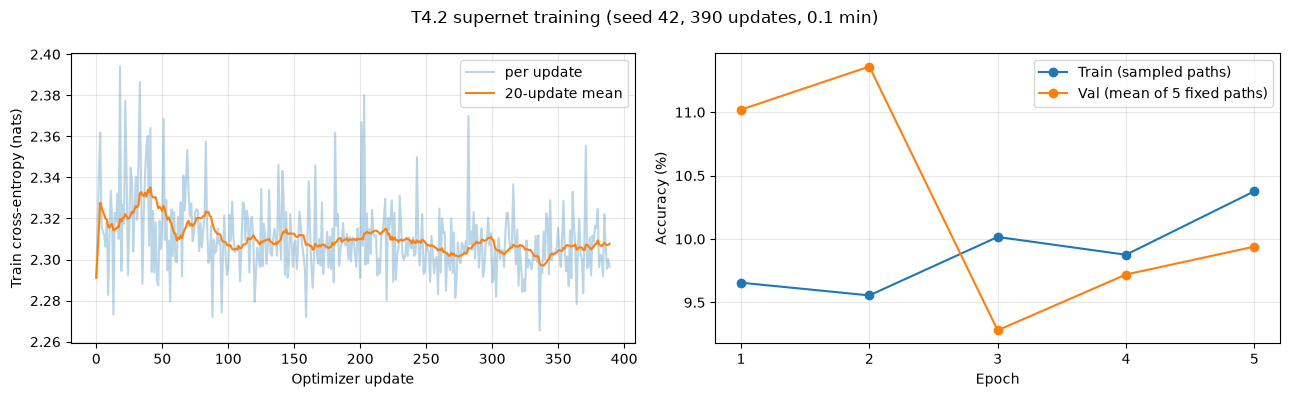

How often each op was sampled (expected ~ 97 each):


/var/folders/7f/yydc1y1j4cdb99h28qt8p4yh0000gn/T/ipykernel_68870/797682824.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  counts_df["total"] = counts_df.sum(1)


,conv3x3,conv5x5,dwsep3x3,identity,total
block 0,90,94,102,104,390
block 1,93,96,103,98,390
block 2,105,95,90,100,390
block 3,100,86,106,98,390


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(step_loss, alpha=.3, label="per update")
ax[0].plot(pd.Series(step_loss).rolling(20, min_periods=1).mean(), label="20-update mean")
ax[0].set_xlabel("Optimizer update"); ax[0].set_ylabel("Train cross-entropy (nats)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.epoch, hist.train_acc, "o-", label="Train (sampled paths)")
ax[1].plot(hist.epoch, hist.val_acc_5_paths, "o-", label="Val (mean of 5 fixed paths)")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_xticks(hist.epoch); ax[1].legend(); ax[1].grid(alpha=.3)
plt.suptitle(f"T4.2 supernet training (seed {SEED}, {n_updates} updates, {train_min:.1f} min)"); plt.tight_layout()
plt.savefig(f"{OUT}/t4_2_curves.png", dpi=150); plt.show()

counts_df = pd.DataFrame(counts, columns=OPS, index=[f"block {b}" for b in range(N_BLOCKS)])
counts_df["total"] = counts_df.sum(1)
print("How often each op was sampled (expected ~", n_updates // len(OPS), "each):"); display(counts_df)
counts_df.to_csv(f"{OUT}/t4_2_sampling_counts.csv")

## T4.3 · Subnetwork Adaptation
### 4.3‑a · 12 distinct subnetworks: accuracy after 0, 10 and 30 updates

In [33]:
def adapt(path):
    """Independent run: fresh copy from the SAME checkpoint, same minibatch order for every subnet."""
    sn = Supernet().to(DEVICE); sn.load_state_dict(torch.load(f"{OUT}/supernet.pt"))
    sub = SubNet(sn, path).to(DEVICE)
    opt = torch.optim.AdamW(sub.parameters(), lr=ADAPT_LR, weight_decay=WD)
    gen = torch.Generator().manual_seed(SEED)
    acc = {0: evaluate(sub)[1]}
    for step in range(1, 31):                                     # 30-step run continues from step 10
        idx = torch.randint(len(Xtr), (BATCH,), generator=gen)
        loss = F.cross_entropy(sub(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        if step in (10, 30): acc[step] = evaluate(sub)[1]
    return acc, count_params(sub)


rng = random.Random(SEED + 1); paths = []
while len(paths) < N_SUBNETS:
    p = sample_path(rng)
    if p not in paths: paths.append(p)

rows = []
for k, p in enumerate(paths):
    acc, n_params = adapt(p)
    rows.append({"id": k, "path": p, "ops": path_name(p), "params": n_params,
                 "acc_0": acc[0], "acc_10": acc[10], "acc_30": acc[30]})
    print(rows[-1])
res = pd.DataFrame(rows)
for s in [0, 10, 30]:
    res[f"rank_{s}"] = res[f"acc_{s}"].rank(ascending=False, method="min").astype(int)   # 1 = best
res.to_csv(f"{OUT}/t4_3_adaptation.csv", index=False)
display(res)

{'id': 0, 'path': (0, 2, 1, 3), 'ops': 'conv3x3-dwsep3x3-conv5x5-identity', 'params': 9834, 'acc_0': 14.0, 'acc_10': 12.5, 'acc_30': 18.9}
{'id': 1, 'path': (2, 0, 3, 3), 'ops': 'dwsep3x3-conv3x3-identity-identity', 'params': 3402, 'acc_0': 10.2, 'acc_10': 13.4, 'acc_30': 14.3}
{'id': 2, 'path': (0, 3, 2, 3), 'ops': 'conv3x3-identity-dwsep3x3-identity', 'params': 3402, 'acc_0': 10.3, 'acc_10': 12.0, 'acc_30': 9.8}
{'id': 3, 'path': (3, 1, 0, 0), 'ops': 'identity-conv5x5-conv3x3-conv3x3', 'params': 11738, 'acc_0': 9.0, 'acc_10': 10.0, 'acc_30': 17.3}
{'id': 4, 'path': (0, 3, 1, 0), 'ops': 'conv3x3-identity-conv5x5-conv3x3', 'params': 11738, 'acc_0': 10.7, 'acc_10': 14.0, 'acc_30': 18.4}
{'id': 5, 'path': (1, 3, 1, 3), 'ops': 'conv5x5-identity-conv5x5-identity', 'params': 13498, 'acc_0': 10.0, 'acc_10': 10.3, 'acc_30': 16.6}
{'id': 6, 'path': (2, 1, 3, 0), 'ops': 'dwsep3x3-conv5x5-identity-conv3x3', 'params': 9834, 'acc_0': 13.6, 'acc_10': 13.0, 'acc_30': 15.4}
{'id': 7, 'path': (0, 0, 1

,id,path,ops,params,acc_0,acc_10,acc_30,rank_0,rank_10,rank_30
0,0,"(0, 2, 1, 3)",conv3x3-dwsep3x3-conv5x5-identity,9834,14.0,12.5,18.9,1,5,1
1,1,"(2, 0, 3, 3)",dwsep3x3-conv3x3-identity-identity,3402,10.2,13.4,14.3,8,3,10
2,2,"(0, 3, 2, 3)",conv3x3-identity-dwsep3x3-identity,3402,10.3,12.0,9.8,7,6,12
3,3,"(3, 1, 0, 0)",identity-conv5x5-conv3x3-conv3x3,11738,9.0,10.0,17.3,12,10,3
4,4,"(0, 3, 1, 0)",conv3x3-identity-conv5x5-conv3x3,11738,10.7,14.0,18.4,5,1,2
5,5,"(1, 3, 1, 3)",conv5x5-identity-conv5x5-identity,13498,10.0,10.3,16.6,9,8,6
6,6,"(2, 1, 3, 0)",dwsep3x3-conv5x5-identity-conv3x3,9834,13.6,13.0,15.4,2,4,9
7,7,"(0, 0, 1, 0)",conv3x3-conv3x3-conv5x5-conv3x3,14074,12.1,11.9,17.3,3,7,3
8,8,"(1, 2, 2, 0)",conv5x5-dwsep3x3-dwsep3x3-conv3x3,10266,9.9,9.8,16.4,10,12,7
9,9,"(0, 0, 0, 3)",conv3x3-conv3x3-conv3x3-identity,7642,10.8,10.0,16.1,4,10,8


### 4.3‑b · Rank correlation and plots

Kendall tau: {'inherited vs 10 steps': np.float64(0.369), 'inherited vs 30 steps': np.float64(0.229), '10 steps vs 30 steps': np.float64(0.109)}
Best inherited: conv3x3-dwsep3x3-conv5x5-identity | best after 30 steps: conv3x3-dwsep3x3-conv5x5-identity
Subnets that changed rank (0 -> 30):


,id,ops,rank_0,rank_10,rank_30
1,1,dwsep3x3-conv3x3-identity-identity,8,3,10
2,2,conv3x3-identity-dwsep3x3-identity,7,6,12
3,3,identity-conv5x5-conv3x3-conv3x3,12,10,3
4,4,conv3x3-identity-conv5x5-conv3x3,5,1,2
5,5,conv5x5-identity-conv5x5-identity,9,8,6
6,6,dwsep3x3-conv5x5-identity-conv3x3,2,4,9
8,8,conv5x5-dwsep3x3-dwsep3x3-conv3x3,10,12,7
9,9,conv3x3-conv3x3-conv3x3-identity,4,10,8
10,10,dwsep3x3-dwsep3x3-identity-conv5x5,6,2,5


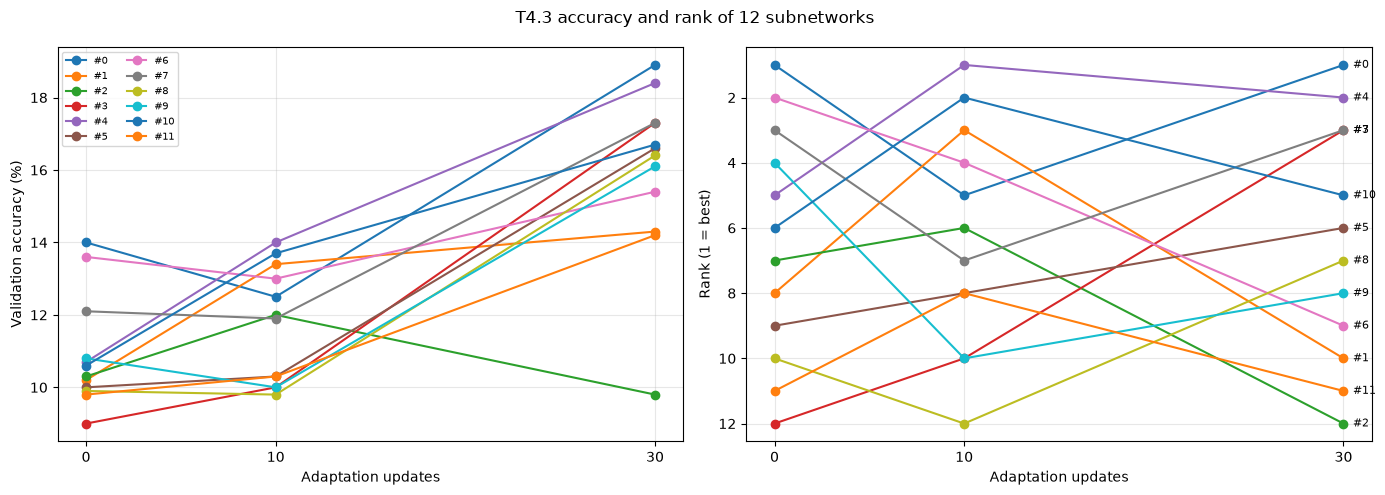

In [34]:
def kendall_tau(a, b):
    """Kendall tau-b (handles ties)."""
    c = d = ta = tb = 0
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            da, db = np.sign(a[i] - a[j]), np.sign(b[i] - b[j])
            if da == 0 and db == 0: continue
            elif da == 0: ta += 1
            elif db == 0: tb += 1
            elif da == db: c += 1
            else: d += 1
    return (c - d) / np.sqrt((c + d + ta) * (c + d + tb))

taus = {"inherited vs 10 steps": kendall_tau(res.acc_0.values, res.acc_10.values),
        "inherited vs 30 steps": kendall_tau(res.acc_0.values, res.acc_30.values),
        "10 steps vs 30 steps":  kendall_tau(res.acc_10.values, res.acc_30.values)}
print("Kendall tau:", {k: round(v, 3) for k, v in taus.items()})
print("Best inherited:", res.loc[res.acc_0.idxmax(), "ops"], "| best after 30 steps:", res.loc[res.acc_30.idxmax(), "ops"])
print("Subnets that changed rank (0 -> 30):"); display(res[res.rank_0 != res.rank_30][["id", "ops", "rank_0", "rank_10", "rank_30"]])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for _, r in res.iterrows():
    ax[0].plot([0, 10, 30], [r.acc_0, r.acc_10, r.acc_30], "o-", label=f"#{r.id}")
    ax[1].plot([0, 10, 30], [r.rank_0, r.rank_10, r.rank_30], "o-")
    ax[1].text(30.5, r.rank_30, f"#{r.id}", va="center", fontsize=8)
ax[0].set_xlabel("Adaptation updates"); ax[0].set_ylabel("Validation accuracy (%)"); ax[0].legend(fontsize=7, ncol=2)
ax[1].set_xlabel("Adaptation updates"); ax[1].set_ylabel("Rank (1 = best)"); ax[1].invert_yaxis()
for a in ax: a.set_xticks([0, 10, 30]); a.grid(alpha=.3)
plt.suptitle("T4.3 accuracy and rank of 12 subnetworks"); plt.tight_layout()
plt.savefig(f"{OUT}/t4_3_adaptation.png", dpi=150); plt.show()

## T4.4 · Compare with Training from Scratch
### 4.4 · Best-after-30 plus one random different architecture, each trained from scratch for 5 epochs

,Architecture,ops,params,Inherited (%),Adapted 10 (%),Adapted 30 (%),From scratch 5 ep (%),Scratch updates
0,Best after 30 steps,conv3x3-dwsep3x3-conv5x5-identity,9834,14.0,12.5,18.9,26.7,390
1,Random other,conv3x3-conv3x3-conv5x5-conv3x3,14074,12.1,11.9,17.3,27.0,390


Ranking by inherited : ['Best after 30 steps', 'Random other']
Ranking by adapted 30: ['Best after 30 steps', 'Random other']
Ranking by scratch   : ['Random other', 'Best after 30 steps']


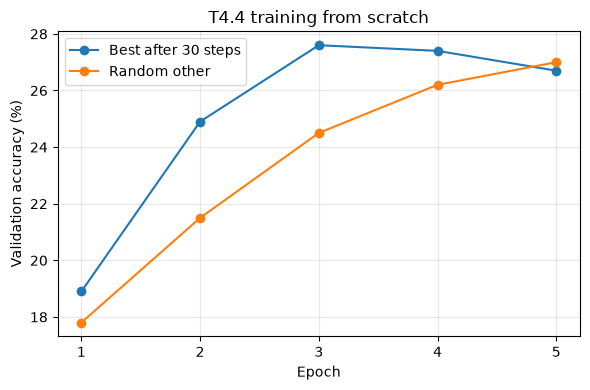

In [35]:
def train_from_scratch(path):
    set_seed()                                                    # identical settings for both
    sub = SubNet(Supernet(), path).to(DEVICE)                     # fresh random weights
    opt = torch.optim.AdamW(sub.parameters(), lr=LR, weight_decay=WD)
    steps = len(Xtr) // BATCH
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * steps)
    gen, accs = torch.Generator().manual_seed(SEED), []
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(Xtr), generator=gen)
        for s in range(steps):
            idx = perm[s * BATCH:(s + 1) * BATCH]
            loss = F.cross_entropy(sub(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        accs.append(evaluate(sub)[1])
    return accs, EPOCHS * steps

best_id = int(res.acc_30.idxmax())
other_id = random.Random(SEED + 2).choice([i for i in range(N_SUBNETS) if i != best_id])

rows, curves = [], {}
for tag, i in [("Best after 30 steps", best_id), ("Random other", other_id)]:
    accs, upd = train_from_scratch(res.path[i]); curves[tag] = accs
    rows.append({"Architecture": tag, "ops": res.ops[i], "params": res.params[i],
                 "Inherited (%)": res.acc_0[i], "Adapted 10 (%)": res.acc_10[i], "Adapted 30 (%)": res.acc_30[i],
                 "From scratch 5 ep (%)": accs[-1], "Scratch updates": upd})
cmp = pd.DataFrame(rows); cmp.to_csv(f"{OUT}/t4_4_comparison.csv", index=False)
display(cmp)

order = lambda col: cmp.sort_values(col, ascending=False).Architecture.tolist()
print("Ranking by inherited :", order("Inherited (%)"))
print("Ranking by adapted 30:", order("Adapted 30 (%)"))
print("Ranking by scratch   :", order("From scratch 5 ep (%)"))

plt.figure(figsize=(6, 4))
for tag, accs in curves.items():
    plt.plot(range(1, EPOCHS + 1), accs, "o-", label=tag)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy (%)"); plt.xticks(range(1, EPOCHS + 1))
plt.title("T4.4 training from scratch"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/t4_4_scratch.png", dpi=150); plt.show()

# T5.1 · Random Search

### Setup, encoding and benchmark lookup

In [36]:
import os, random
from collections import deque
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nats_bench import create

OPS = ["none", "skip_connect", "nor_conv_1x1", "nor_conv_3x3", "avg_pool_3x3"]
N_EDGES, BUDGET, SEEDS = 6, 100, [0, 1, 2]
DATASET, HP = "cifar10-valid", "200"              # CIFAR-10 validation accuracy after 200 epochs
OUT = "task5_outputs"; os.makedirs(OUT, exist_ok=True)

NATS_PATH = "NATS-tss-v1_0-3ffb9-simple"          # benchmark folder inside Assignment 4
assert os.path.isdir(NATS_PATH), f"Benchmark folder not found: {os.path.abspath(NATS_PATH)}"
api = create(NATS_PATH, "tss", fast_mode=True, verbose=False)
print(f"Search space size: {len(OPS)}^{N_EDGES} = {len(OPS) ** N_EDGES}")


def to_str(arch):
    """Encoding: 6 op indices for edges (0->1, 0->2, 1->2, 0->3, 1->3, 2->3) -> NATS-Bench string."""
    o = [OPS[i] for i in arch]
    return f"|{o[0]}~0|+|{o[1]}~0|{o[2]}~1|+|{o[3]}~0|{o[4]}~1|{o[5]}~2|"


def random_arch(rng):
    """Uniform sampling: each of the 6 edges picks one of 5 ops."""
    return tuple(rng.randrange(len(OPS)) for _ in range(N_EDGES))


_cache = {}
def evaluate(arch):
    """Benchmark lookup of validation accuracy (%) - no training."""
    if arch not in _cache:
        idx = api.query_index_by_arch(to_str(arch))
        _cache[arch] = api.get_more_info(idx, DATASET, hp=HP, is_random=False)["valid-accuracy"]
    return _cache[arch]


ex = random_arch(random.Random(0))
print("Example architecture:", ex)
print("NATS-Bench string   :", to_str(ex))
print(f"Validation accuracy : {evaluate(ex):.2f}%")

Search space size: 5^6 = 15625
Example architecture: (3, 3, 0, 2, 4, 3)
NATS-Bench string   : |nor_conv_3x3~0|+|nor_conv_3x3~0|none~1|+|nor_conv_1x1~0|avg_pool_3x3~1|nor_conv_3x3~2|
Validation accuracy : 89.85%


### Random search: 100 evaluations × 3 seeds

,Seed,Best val acc (%),Best architecture
0,0,90.83,|nor_conv_3x3~0|+|nor_conv_3x3~0|avg_pool_3x3~...
1,1,91.32,|nor_conv_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~...
2,2,91.30,|nor_conv_3x3~0|+|nor_conv_3x3~0|avg_pool_3x3~...


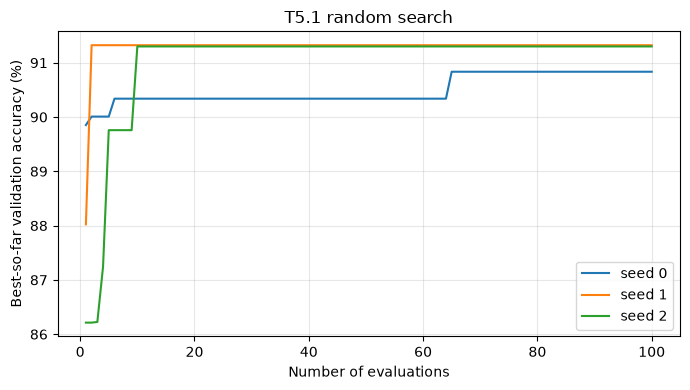

In [37]:
def random_search(seed):
    rng, best, best_arch, curve = random.Random(seed), -1.0, None, []
    for _ in range(BUDGET):
        arch = random_arch(rng)
        acc = evaluate(arch)
        if acc > best:
            best, best_arch = acc, arch
        curve.append(best)                         # best-so-far after each evaluation
    return np.array(curve), best_arch


rs = {s: random_search(s) for s in SEEDS}
rs_table = pd.DataFrame([{"Seed": s, "Best val acc (%)": round(c[-1], 2), "Best architecture": to_str(a)}
                         for s, (c, a) in rs.items()])
rs_table.to_csv(f"{OUT}/t5_1_random_search.csv", index=False)
display(rs_table)

plt.figure(figsize=(7, 4))
for s, (c, _) in rs.items():
    plt.plot(range(1, BUDGET + 1), c, label=f"seed {s}")
plt.xlabel("Number of evaluations"); plt.ylabel("Best-so-far validation accuracy (%)")
plt.title("T5.1 random search"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/t5_1_random_search.png", dpi=150); plt.show()

## T5.2 · Aging Evolution
### · Aging evolution: population 10, sample 3, 100 evaluations including initialization

In [38]:
POP_SIZE, SAMPLE_SIZE = 10, 3


def mutate(arch, rng):
    """Change one random edge to a DIFFERENT operation."""
    arch = list(arch)
    e = rng.randrange(N_EDGES)
    arch[e] = rng.choice([o for o in range(len(OPS)) if o != arch[e]])
    return tuple(arch)


def aging_evolution(seed):
    rng, pop = random.Random(seed), deque()                  # left end = oldest member
    best_curve, pop_best_curve, trace = [], [], []

    def log(step, arch, acc):
        best_curve.append(max(acc, best_curve[-1] if best_curve else -1.0))
        pop_best_curve.append(max(a for _, a in pop))
        trace.append({"eval": len(best_curve), "step": step, "arch": to_str(arch), "acc": round(acc, 2),
                      "pop size": len(pop), "pop best": round(pop_best_curve[-1], 2), "best ever": round(best_curve[-1], 2)})

    # Initialization: 10 random architectures (counted in the 100-evaluation budget)
    for _ in range(POP_SIZE):
        arch = random_arch(rng)
        pop.append((arch, evaluate(arch)))
        log("init", arch, pop[-1][1])

    # Evolution: remaining 90 evaluations
    while len(best_curve) < BUDGET:
        candidates = rng.sample(list(pop), SAMPLE_SIZE)     # 1) sample 3 members
        parent = max(candidates, key=lambda m: m[1])         # 2) take the best of the 3
        child = mutate(parent[0], rng)                       # 3) mutate one edge
        pop.append((child, evaluate(child)))                 # 4) evaluate and add
        pop.popleft()                                        # 5) remove the oldest
        assert len(pop) == POP_SIZE                          # population-size check
        log("mutate", child, pop[-1][1])

    return np.array(best_curve), np.array(pop_best_curve), pd.DataFrame(trace)


ae = {s: aging_evolution(s) for s in SEEDS}
for s, (best, pop_best, trace) in ae.items():
    print(f"seed {s}: best-ever {best[-1]:.2f}% | evaluations {len(best)} | "
          f"population size after init: {sorted(set(trace['pop size'][POP_SIZE:]))} | "
          f"population best ever decreased: {bool(np.any(np.diff(pop_best) < 0))}")

print("\nExecution trace (seed 0, first 15 evaluations):")
display(ae[SEEDS[0]][2].head(15))
ae[SEEDS[0]][2].to_csv(f"{OUT}/t5_2_trace_seed0.csv", index=False)

seed 0: best-ever 91.33% | evaluations 100 | population size after init: [10] | population best ever decreased: True
seed 1: best-ever 91.55% | evaluations 100 | population size after init: [10] | population best ever decreased: True
seed 2: best-ever 91.53% | evaluations 100 | population size after init: [10] | population best ever decreased: True

Execution trace (seed 0, first 15 evaluations):


,eval,step,arch,acc,pop size,pop best,best ever
0,1,init,|nor_conv_3x3~0|+|nor_conv_3x3~0|none~1|+|nor_...,89.85,1,89.85,89.85
1,2,init,|nor_conv_3x3~0|+|nor_conv_1x1~0|nor_conv_3x3~...,90.01,2,90.01,90.01
2,3,init,|avg_pool_3x3~0|+|skip_connect~0|nor_conv_1x1~...,81.49,3,90.01,90.01
3,4,init,|nor_conv_1x1~0|+|avg_pool_3x3~0|avg_pool_3x3~...,87.75,4,90.01,90.01
4,5,init,|none~0|+|nor_conv_1x1~0|nor_conv_3x3~1|+|avg_...,86.46,5,90.01,90.01
5,6,init,|nor_conv_3x3~0|+|nor_conv_1x1~0|avg_pool_3x3~...,90.34,6,90.34,90.34
6,7,init,|nor_conv_3x3~0|+|avg_pool_3x3~0|nor_conv_1x1~...,84.36,7,90.34,90.34
7,8,init,|none~0|+|nor_conv_3x3~0|none~1|+|avg_pool_3x3...,88.43,8,90.34,90.34
8,9,init,|skip_connect~0|+|nor_conv_1x1~0|none~1|+|skip...,83.74,9,90.34,90.34
9,10,init,|skip_connect~0|+|skip_connect~0|avg_pool_3x3~...,88.40,10,90.34,90.34


### Curves: current population best vs best-ever

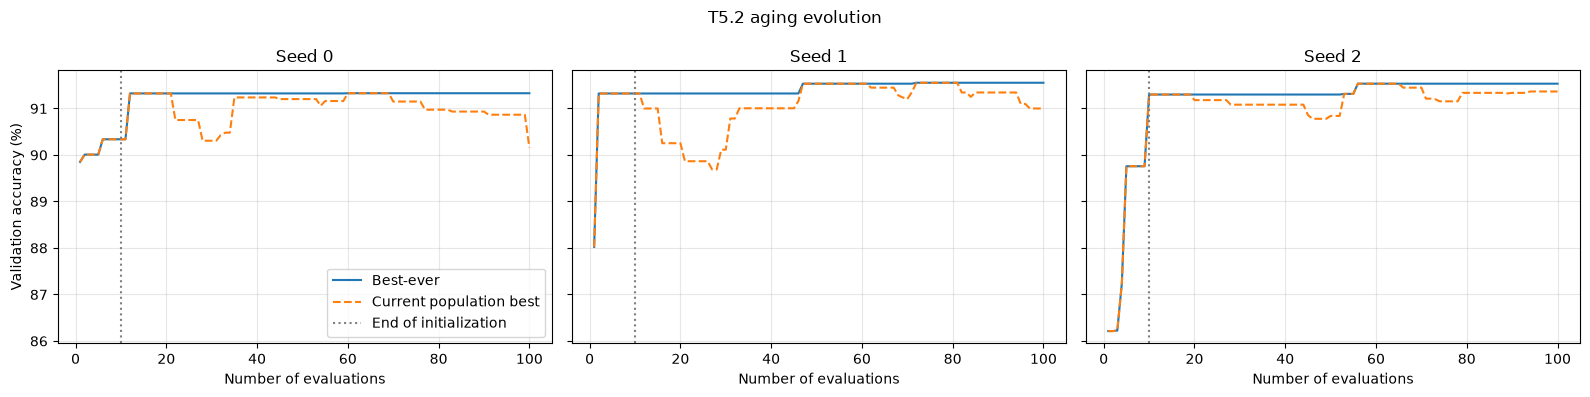

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (s, (best, pop_best, _)) in zip(axes, ae.items()):
    x = range(1, BUDGET + 1)
    ax.plot(x, best, label="Best-ever")
    ax.plot(x, pop_best, "--", label="Current population best")
    ax.axvline(POP_SIZE, c="gray", ls=":", label="End of initialization")
    ax.set_title(f"Seed {s}"); ax.set_xlabel("Number of evaluations"); ax.grid(alpha=.3)
axes[0].set_ylabel("Validation accuracy (%)"); axes[0].legend()
plt.suptitle("T5.2 aging evolution"); plt.tight_layout()
plt.savefig(f"{OUT}/t5_2_aging_evolution.png", dpi=150); plt.show()

## T5.3 · Compare the Methods
### · Best, mean and std across 3 seeds, plus the comparison plot

,Method,Best (%),Mean (%),Std (%),Seed 0 (%),Seed 1 (%),Seed 2 (%)
0,Random search,91.32,91.15,0.23,90.83,91.32,91.30
1,Aging evolution,91.55,91.47,0.10,91.33,91.55,91.53


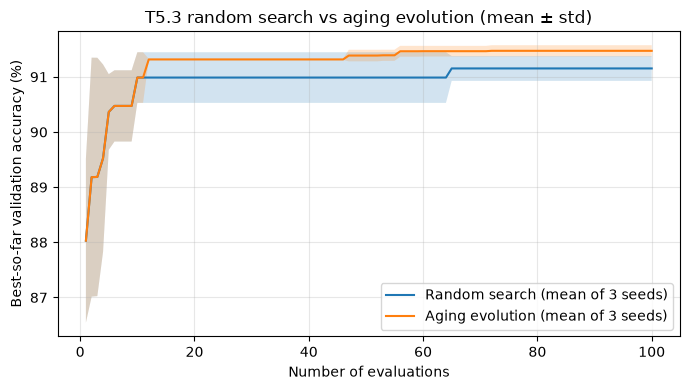

In [40]:
curves = {"Random search": np.array([rs[s][0] for s in SEEDS]),
          "Aging evolution": np.array([ae[s][0] for s in SEEDS])}

summary = pd.DataFrame([{"Method": m, "Best (%)": c[:, -1].max(), "Mean (%)": c[:, -1].mean(), "Std (%)": c[:, -1].std(),
                         **{f"Seed {s} (%)": c[i, -1] for i, s in enumerate(SEEDS)}}
                        for m, c in curves.items()]).round(2)
summary.to_csv(f"{OUT}/t5_3_summary.csv", index=False)
display(summary)

plt.figure(figsize=(7, 4))
x = np.arange(1, BUDGET + 1)
for m, c in curves.items():
    plt.plot(x, c.mean(0), label=f"{m} (mean of 3 seeds)")
    plt.fill_between(x, c.mean(0) - c.std(0), c.mean(0) + c.std(0), alpha=.2)
plt.xlabel("Number of evaluations"); plt.ylabel("Best-so-far validation accuracy (%)")
plt.title("T5.3 random search vs aging evolution (mean ± std)"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/t5_3_comparison.png", dpi=150); plt.show()